# Session 7, soil moisture track: water in the top metre of soil at Turnbull

📍 In-situ sensor · 💧 Land water · 💧 Hydrology & land-surface modeling

**Updated 14 October, afternoon:** more cells where you write the analysis yourself. If you already finished the earlier version, submit it as is.

**Wednesday 14 October 2026, self-guided.** Each question has a self-check and a collapsed worked solution; open it after you have tried.

**Learning outcomes.** After this session you can:

- tell whether a station file was modified or corrupted;
- state what a soil moisture probe samples and what processing lies between it and a daily value;
- read a daily station table: rows, units, missing-value codes, limits, a real extreme against an error;
- find and clean sensor and processing problems, and measure how each biases the soil's response to rain;
- separate a shared seasonal cycle from day-to-day coupling in a correlation;
- write the chain from a raw file to a learning problem without leaks;
- write rules and instructions that let another person, or an AI tool, rerun your chain from the ten NCEI yearly files to the response to rain at 5 cm, and check whether it did.

**Objectives for today.** You will:

- download ten years of daily soil moisture at five depths from NCEI and check your copy;
- read the 5 cm series and the depth-by-time field, and date a wetting front;
- hunt six problems planted in a synthetic twin and compute the response to rain three ways;
- correlate precipitation, temperature and soil moisture with and without the seasonal cycle;
- frame a dry-spell problem for machine learning;
- start the two agent skill files you submit on Friday.

**How to work.** Work in a copy, `lab_s07_soil_moisture_UWNETID.ipynb`, here, opened with `pixi run jupyter lab`; do not commit, push or stash in the book clone. Edit `NETID` in the first code cell: it places the problems in your twin. Replace each `...` or `""` and run the self-check below it. In a **Your turn** cell you write the analysis, 2 to 5 lines: replace each `None` with your code and run the cell; its self-check says whether the result is right, and a collapsed worked solution follows. If you leave a `None`, the next cells continue with a reference result and say so. The times are rough estimates of how long each part takes, not a schedule. Parts 4 and 8, Your turn 6b, Your turn 7b with Question 7.3, and the hunt in Part 5 beyond three findings are for when you have time; skip them if you want more time for the rest.

**Submit** by Friday 16 October, 9:00, to the Canvas assignment "Session 7: explore your system's data": this notebook (.ipynb; HTML optional), the three files of Part 8 and a short comment. Completion only: the work does not count toward your grade, but a missing submission costs 10 points.

**Not using `git pull`?** Download this track as one zip, [lab_s07_soil_moisture.zip](https://geo-smart.github.io/mlgeo-book/downloads/lab_s07_soil_moisture.zip), unzip it and open the notebook from the unzipped folder; the [start page](lab_s07_start_here.md) explains how.

In [1]:
# Run this cell first. Put your UW NetID between the quotes (for example "jdoe42").
NETID = ""

import hashlib
import json
import os
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import xarray as xr
from scipy import stats

import lab_s07_soil_checks as check
import lab_s07_soil_synthetic as soil
from lab_s07_soil_synthetic import PROBLEM_TYPES, check_findings, rain_response

SNAP = Path("snapshots")                                   # course copies, committed with the book
WORK = Path("s07_my_files")                               # your downloads and files (ignored by git)
WORK.mkdir(parents=True, exist_ok=True)
COURSE_FILE = SNAP / "uscrn_WA_Spokane_17_SSW_2015-2024.txt"
PROV = json.loads((SNAP / "uscrn_WA_Spokane_17_SSW_2015-2024.provenance.json").read_text())
OFFLINE = bool(os.environ.get("CI")) or os.environ.get("MLGEO_OFFLINE") == "1"
DEPTHS = [5, 10, 20, 50, 100]                              # probe depths, cm
pd.set_option("display.width", 160)
print(f"NetID: {NETID or '(empty: you get the class twin, the one the worked solutions use)'}   "
      f"offline mode: {OFFLINE}   course copy: {COURSE_FILE}")

NetID: (empty: you get the class twin, the one the worked solutions use)   offline mode: True   course copy: snapshots/uscrn_WA_Spokane_17_SSW_2015-2024.txt


## Part 0. The system and the question (about 3 min)

The top metre of soil is a small reservoir: rain and snowmelt fill it; evaporation, root uptake and drainage empty it. How full it is decides whether a storm soaks in or runs off, how long plants grow into the dry season, and how much water recharges the aquifer. Drought monitors and weather and climate models track it for these reasons.

**WA Spokane 17 SSW** is a station of the U.S. Climate Reference Network (USCRN), run by the National Oceanic and Atmospheric Administration (NOAA) and distributed by its National Centers for Environmental Information (NCEI). It sits in Turnbull National Wildlife Refuge, on the channeled scablands south of Spokane, where Ice Age floods scoured the basalt. Summers are dry, winters wet and cold. Soil probes were added in 2009 to 2011 for drought monitoring, with the National Integrated Drought Information System (<https://www.ncei.noaa.gov/access/crn/why.html>); Bell et al. (2013, doi:10.1175/JHM-D-12-0146.1) describe the network.

**Guiding question:** *When it rains at Turnbull, how much water does the top of the soil take up, how does it move down the profile, and how does this change through the year?*

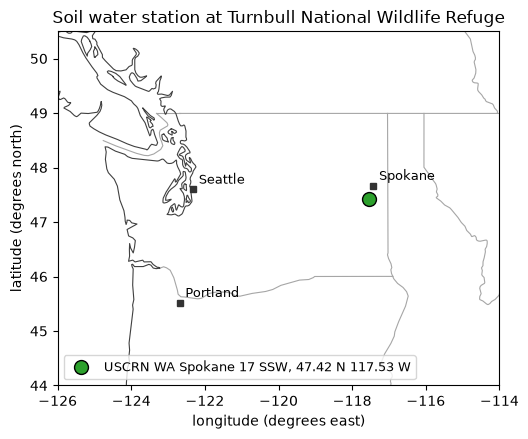

NCEI station list: US Fish & Wildlife Service, Turnbull NWR (Headquarters Site), 47.41 N, 117.52 W, commissioned 2007-09-28, status Commissioned


In [2]:
# Where the station is: coastline, borders and three cities from Natural Earth (public domain),
# station coordinates from fields 4 and 5 of the data file itself.
mp = pd.read_csv(SNAP / "naturalearth_pnw_map.csv")
first = pd.read_csv(COURSE_FILE, sep=r"\s+", header=None, nrows=1)
lon, lat = float(first[3].iloc[0]), float(first[4].iloc[0])

fig, ax = plt.subplots(figsize=(7, 4.6))
for (kind, part), seg in mp[mp["kind"] != "place"].groupby(["kind", "part"]):
    ax.plot(seg["lon"], seg["lat"], color="0.25" if kind == "coastline" else "0.65", lw=0.8)
for _, p in mp[mp["kind"] == "place"].iterrows():
    ax.plot(p["lon"], p["lat"], "s", color="0.2", ms=4)
    ax.annotate(p["name"], (p["lon"], p["lat"]), xytext=(4, 4), textcoords="offset points", fontsize=9)
ax.plot(lon, lat, "o", color="tab:green", mec="k", ms=10,
        label=f"USCRN WA Spokane 17 SSW, {lat:.2f} N {abs(lon):.2f} W")
ax.set_xlim(-126, -114)
ax.set_ylim(44, 50.5)
ax.set_aspect(1 / np.cos(np.deg2rad(47.5)))                  # equal distances at this latitude
ax.set(xlabel="longitude (degrees east)", ylabel="latitude (degrees north)",
       title="Soil water station at Turnbull National Wildlife Refuge")
ax.legend(loc="lower left", fontsize=9)
plt.show()
row = PROV["station_list_row"]
print(f"NCEI station list: {row['NAME']}, {row['LATITUDE']} N, {abs(float(row['LONGITUDE']))} W, "
      f"commissioned {row['COMMISSIONING'][:10]}, status {row['STATUS']}")

```{admonition} 🔒 By hand
:class: attention
No AI tool for the judgment in this step: state what you expect before you run anything, decide with a physical reason, and read the result against your expectation ([1.8](../Chapter1-GettingStarted/1.8_ai_in_your_workflow.md)).
```

**Question 0.1.** Predict the month (1 to 12) in which the soil at 5 cm is wettest on average, and the driest. Part 3 checks it.

In [3]:
predict_wettest_month = ...
predict_driest_month = ...
check.check_prediction(predict_wettest_month, predict_driest_month)

not answered yet


```{admonition} If you are stuck
:class: tip
- `NameError` or `ModuleNotFoundError`: run the first code cell; start Jupyter with `pixi run jupyter lab` from the book clone.
- Empty map: open the notebook from `book/Chapter2-DataManipulation/`, beside `snapshots/`.
```

## Part 1. Download the raw data and know what you have (about 15 min)

NCEI serves one file per station and year at <https://www.ncei.noaa.gov/pub/data/uscrn/products/daily01/>. The next cell downloads the ten files of 2015 to 2024 (0.8 MB) and joins them in year order, as `snapshots/make_uscrn_WA_Spokane_17_SSW_2015-2024.py` built the course copy. Without a network, it uses the course copy.

In [4]:
BASE = "https://www.ncei.noaa.gov/pub/data/uscrn/products/daily01"
STATION = "WA_Spokane_17_SSW"
my_file = WORK / "my_download_uscrn_WA_Spokane_17_SSW_2015-2024.txt"
my_years = {}
if OFFLINE:
    print("Offline mode: no download. You will work from the course copy in snapshots/.")
else:
    import requests
    try:
        for year in range(2015, 2025):
            url = f"{BASE}/{year}/CRND0103-{year}-{STATION}.txt"
            r = requests.get(url, timeout=20)
            r.raise_for_status()
            my_years[year] = (url, r.content, r.headers.get("Last-Modified"))
        my_file.write_bytes(b"".join(my_years[y][1] for y in sorted(my_years)))
        print(f"Downloaded {len(my_years)} files from {BASE}/ into {my_file}")
    except Exception as err:                       # no network, timeout, server error
        my_years = {}
        print(f"Download failed ({type(err).__name__}). Falling back to the course copy in snapshots/.")

Offline mode: no download. You will work from the course copy in snapshots/.


### Has the file been modified or corrupted?

Four checks, cheapest first:

1. **Size in bytes.** A transfer that stopped early gives a smaller file.
2. **Number of rows.** One per calendar day.
3. **First and last records.** Does the file start and end where it should?
4. **Fingerprint.** SHA-256 (Secure Hash Algorithm, 256-bit) turns every byte into a 64-character code; one changed byte changes the code completely. NCEI publishes none for these files, so the course recorded one per file (`served` in the provenance file).

A different fingerprint does not by itself mean damage: NCEI revises its data. README section 2 lists three reprocessings of precipitation (2015, 2016, 2017), and NCEI's notice of 20 October 2022 says every soil moisture value was rerun "for all stations and the period of record" after dry readings had been set to zero instead of flagged. Find which years changed, then compare values.

In [5]:
def describe_file(path):
    """Size, rows, first and last records, and SHA-256 fingerprint of a text file."""
    b = Path(path).read_bytes()
    lines = b.decode("ascii").splitlines()
    return {"bytes": len(b), "rows": len(lines), "start of first record": lines[0][:24],
            "end of last record": lines[-1][-24:], "fingerprint (SHA-256)": hashlib.sha256(b).hexdigest()}


course = describe_file(COURSE_FILE)
print("course copy fingerprint matches the one recorded when it was built:", course["fingerprint (SHA-256)"] == PROV["sha256"])
comparison = None
if my_years and my_file.exists():
    mine = describe_file(my_file)
    comparison = pd.DataFrame({"course copy": course, "your download": mine})
    comparison.loc["same fingerprint"] = [course["fingerprint (SHA-256)"] == mine["fingerprint (SHA-256)"]] * 2
    per_year = pd.DataFrame([{"year": y, "Last-Modified now": lm, "recorded when built": PROV["served"][u]["last_modified"],
                              "same bytes": hashlib.sha256(b).hexdigest() == PROV["served"][u]["sha256"]}
                             for y, (u, b, lm) in sorted(my_years.items())]).set_index("year")
    display(comparison)
    display(per_year)
else:
    display(pd.DataFrame({"course copy": course}))

course copy fingerprint matches the one recorded when it was built: True


,course copy
bytes,792701
rows,3653
start of first record,04136 20150101 2.422 -1
end of last record,2.7 3.6 3.8
fingerprint (SHA-256),115f60bc36f8aed6ea8d916da42b5e14bb0a5361ecbf05...


The next cell writes two damaged copies to `s07_my_files/`: one digit changed (0.266 becomes 0.267 in the first row), and 100 bytes cut from the end. The edited copy passes every check but the fingerprint; the short copy keeps its row count, but its size and last record give it away.

In [6]:
good = COURSE_FILE.read_bytes()
edited = good.replace(b"  0.266   0.233", b"  0.267   0.233", 1)
(WORK / "edited_copy.txt").write_bytes(edited)
(WORK / "truncated_copy.txt").write_bytes(good[:-100])
demo = pd.DataFrame({name: describe_file(p) for name, p in
                     [("course copy", COURSE_FILE), ("one digit changed", WORK / "edited_copy.txt"),
                      ("cut short", WORK / "truncated_copy.txt")]})
demo.loc["fingerprint (SHA-256)"] = demo.loc["fingerprint (SHA-256)"].str[:20] + "..."
demo

,course copy,one digit changed,cut short
bytes,792701,792701,792601
rows,3653,3653,3653
start of first record,04136 20150101 2.422 -1,04136 20150101 2.422 -1,04136 20150101 2.422 -1
end of last record,2.7 3.6 3.8,2.7 3.6 3.8,6.0 -5.6 -0.8 9
fingerprint (SHA-256),115f60bc36f8aed6ea8d...,bb71e8df329d191268c2...,bf007e1826bbc7fa8a94...


**Question 1.1.** How many rows must the file have if no day is missing or repeated, 1 January 2015 to 31 December 2024? Count by hand.

**Question 1.2.** Is your download byte for byte the course copy (`True` or `False`)? Skip it if you could not download.

In [7]:
n_days_expected = ...
my_copy_matches = ...
check.check_n_rows(n_days_expected)
check.check_download(my_copy_matches, comparison)

not answered yet
No download to compare (offline or skipped). You are working from the course copy, which is fine.


In [8]:
# Worked solution, open after you tried
n_days = len(pd.date_range("2015-01-01", "2024-12-31"))     # 2016, 2020 and 2024 are leap years
print("days in the calendar:", n_days, "  rows in the course copy:", course["rows"])
check.check_n_rows(n_days)
if comparison is not None:
    check.check_download(bool(comparison.loc["same fingerprint"].iloc[0]), comparison)

days in the calendar: 3653   rows in the course copy: 3653
correct. One line per day, no day missing and none repeated. A file that ends early or repeats a day fails here.


### Native resolution: what the probe measures and what the file gives you

The provider's words (copies under `sensor_documentation` in the provenance file):

- NCEI, *What is measured* (<https://www.ncei.noaa.gov/access/crn/measurements.html>): "15 [...] Hydra Probe II (SDI-12) units are placed in the ground in three plots at five depths [...]. These probes use reflected electromagnetic radio waves at 50 MHz to determine the dielectric permittivity of the soil [...], which can be converted to volumetric soil moisture [...] by use of a calibration equation. [...] All 15 probes are interrogated every two minutes and their measurements averaged over 5-minute periods".
- NCEI notice of 20 October 2022: the conversion is one equation for every station, from Seyfried et al. (2005, doi:10.2136/vzj2004.0148) "with slightly updated coefficients": Volumetric = (0.109 × SQRT(Dielectric)) − 0.179.
- Daily README, note J: "The soil values reported in this dataset are an average of the day's hourly soil measurements which are calculated from the multiple independent measurements." Note E: "When the raw data are flagged as erroneous, these derived values are not calculated, and are instead reported as missing."
- Technical Memorandum USCRN-19-001 (2019), p. 16: "The Hydra probe lacks the ability to measure water content in frozen soils".
- Sensing volume: a cylinder 5.7 cm long and 3.0 cm across (manufacturer, <https://stevenswater.com/products/hydraprobe/>).

The dataset record (doi:10.7289/V5MS3QR9) keeps 5-minute values only at 5 cm, hourly values at all depths, and at one test station each hourly value was a single reading until 27 March 2018 (USCRN-19-001, p. 33). The number of readings behind a daily value at 50 cm is not documented, so give a range.

**Your turn 1.** How much soil and how many readings lie behind one daily value? Compute `v_probe`, the soil volume one probe senses in cm³ (a float; the sensing volume is a cylinder), and two integers for one depth and one day: `n_readings_max` if each of the 3 probes is read every 2 minutes, and `n_readings_min` if each probe gives one reading per hour.

*Hint:* the volume of a cylinder is `np.pi * r**2 * length`, with r half the diameter.

In [9]:
# Your turn 1: replace each None with your code
length_cm, diameter_cm = 5.7, 3.0          # sensing cylinder of one Hydra Probe (manufacturer)
v_probe = None
n_readings_max = None
n_readings_min = None
check.check_probe(v_probe, n_readings_max, n_readings_min)

not answered yet


In [10]:
# Worked solution, open after you tried
ws_v_probe = np.pi * (diameter_cm / 2) ** 2 * length_cm
ws_n_readings_max = 3 * 24 * 60 // 2       # 3 probes, one reading every 2 minutes, 24 hours
ws_n_readings_min = 3 * 24                 # 3 probes, one value per hour, 24 hours
check.check_probe(ws_v_probe, ws_n_readings_max, ws_n_readings_min)

correct. One probe senses about 40 cm3, the three together about 121 cm3, a handful of soil, and one daily value rests on somewhere between 72 and 2160 readings.


Three documented ways the probe misleads, and what each does to a derived number:

1. **One calibration for every soil.** In clay-rich soil (Selma, Alabama) the Hydra Probe read 10 to 15% higher than an Acclima probe, because of "the relatively high electrical conductivity of the clay" (USCRN-19-001, p. 8). A near-constant bias shifts every absolute value and threshold, such as "the driest tenth of days"; the response to rain changes only as much as the bias scales with water content.
2. **Air gaps.** Cracks can give "a 0.000 volumetric observation in soil that was moist" (NCEI notice, October 2022), which pulls the layer mean down.
3. **Dry readings flagged, not zeroed, since 2022.** In the driest weeks a layer mean may rest on the one or two wettest probes, which lifts the dry tail.

```{admonition} 🔒 By hand
:class: attention
No AI tool for the judgment in this step: state what you expect before you run anything, decide with a physical reason, and read the result against your expectation ([1.8](../Chapter1-GettingStarted/1.8_ai_in_your_workflow.md)).
```

**Question 1.3.** From the quotes, fill in the native resolution, and say whether the daily file is raw (what the sensor recorded) or derived (computed from it).

**Question 1.4.** In one or two sentences, name the processing steps between the radio-wave reading in the soil and the number in your file.

In [11]:
native = {
    "probes_per_depth": ...,
    "reading_interval_minutes": ...,     # how often one probe is read
    "file_interval_hours": ...,          # what span one value in this file covers
    "raw_or_derived": ...,               # "raw" or "derived"
}
processing_steps = """
"""
check.check_native(native)
check.check_processing_text(processing_steps)

not answered yet
not answered yet


In [12]:
# Worked solution, open after you tried
ws_native = {"probes_per_depth": 3, "reading_interval_minutes": 2, "file_interval_hours": 24, "raw_or_derived": "derived"}
ws_steps = ("Each probe measures a dielectric permittivity, which a general calibration equation converts to "
            "m3/m3; readings every 2 minutes are averaged to 5 minutes (stored only at 5 cm; deeper probes keep "
            "hourly values), the three probes are combined into hourly "
            "values, readings the provider flags are removed (so the value is missing, as on frozen days), and "
            "the 24 hourly values of the local day are averaged.")
check.check_native(ws_native)
check.check_processing_text(ws_steps)

correct. Each daily value is an average over three probes and many readings, converted from a dielectric measurement by a general equation: a derived product.
correct. You named: conversion from dielectric, averaging, quality control, combining probes.


```{admonition} If you are stuck
:class: tip
- The download fails: try once more, then move on; the course copy holds the same data.
- `reading_interval_minutes` rejected: the probe is read more often than the 5-minute average it outputs.
```

## Part 2. A table: what one row records (about 15 min)

One row is one station-day: station 04136 by its Weather Bureau Army Navy (WBAN) number, and a Local Standard Time (LST) day, midnight to midnight without daylight saving. The file has no header line: names and units are in `snapshots/uscrn_daily01_HEADERS.txt`, definitions in `snapshots/uscrn_daily01_readme.txt`, and fields are separated by spaces (README note A).

In [13]:
header = (SNAP / "uscrn_daily01_HEADERS.txt").read_text().splitlines()
names, units = header[1].split(), header[2].split()
print(len(names), "field names, the first six:", names[:6])

28 field names, the first six: ['WBANNO', 'LST_DATE', 'CRX_VN', 'LONGITUDE', 'LATITUDE', 'T_DAILY_MAX']


**Your turn 2a.** Read the course copy `COURSE_FILE` into `raw`: a pandas DataFrame with one row per line of the file and the 28 names in `names` as columns, indexed by date (a DatetimeIndex made from the `LST_DATE` column, which also stays a column). The file has no header line, and runs of spaces separate the fields.

*Hint:* `pd.read_csv` with `sep=r"\s+"`, `header=None` and `names=`; then assign `pd.to_datetime(..., format="%Y%m%d")` to `raw.index`.

In [14]:
# Your turn 2a: replace each None with your code
raw = None
check.check_raw(raw)

not answered yet


In [15]:
# Worked solution, open after you tried
ws_raw = pd.read_csv(COURSE_FILE, sep=r"\s+", header=None, names=names)
ws_raw.index = pd.to_datetime(ws_raw["LST_DATE"], format="%Y%m%d")
check.check_raw(ws_raw)

correct. 3653 days and 28 fields, indexed by the local date.


In [16]:
raw = check.use_or_reference(raw, check.reference_raw, "raw")
print(raw.shape)
display(pd.DataFrame([units], columns=names, index=["unit"]).iloc[:, [1, 5, 9, 18, 22, 23]])
raw.iloc[:3, [1, 2, 5, 6, 9, 18, 19, 20, 21, 22, 23]]

`raw` is blank or not the expected shape. Using the reference result so you can continue; compare with yours.
(3653, 28)


,LST_DATE,T_DAILY_MAX,P_DAILY_CALC,SOIL_MOISTURE_5_DAILY,SOIL_MOISTURE_100_DAILY,SOIL_TEMP_5_DAILY
unit,YYYYMMDD,Celsius,mm,m^3/m^3,m^3/m^3,Celsius


,LST_DATE,CRX_VN,T_DAILY_MAX,T_DAILY_MIN,P_DAILY_CALC,SOIL_MOISTURE_5_DAILY,SOIL_MOISTURE_10_DAILY,SOIL_MOISTURE_20_DAILY,SOIL_MOISTURE_50_DAILY,SOIL_MOISTURE_100_DAILY,SOIL_TEMP_5_DAILY
date,,,,,,,,,,,
2015-01-01,20150101,2.422,-7.2,-16.9,0.0,-99.0,-99.0,0.266,0.233,0.204,-0.3
2015-01-02,20150102,2.422,-3.7,-7.3,0.3,-99.0,-99.0,0.259,0.227,0.198,-0.3
2015-01-03,20150103,2.422,-1.8,-13.7,1.1,-99.0,-99.0,0.254,0.223,0.193,-0.4


**Question 2.1.** In one sentence: what does one row record, where, and over what span of time? (README section 5, fields 1 and 2, note D.)

**Question 2.2.** What are the units of `SOIL_MOISTURE_5_DAILY`, and which provider file states them?

**Question 2.3.** Which number marks a missing value in the soil moisture fields, and which in the air temperature fields (README note C)?

In [17]:
row_meaning = ""
sm_units, units_source = "", ""
sm_missing_code, t_missing_code = ..., ...
check.check_row_meaning(row_meaning)
check.check_units(sm_units, units_source)
check.check_missing_codes(sm_missing_code, t_missing_code)

not answered yet
not answered yet
not answered yet


In [18]:
# Worked solution, open after you tried
check.check_row_meaning("One row is one Local Standard Time day at the Turnbull station (WBAN 04136): daily air "
                        "temperature, rain total, and daily means of soil moisture and temperature at five depths.")
check.check_units("m^3/m^3", "uscrn_daily01_HEADERS.txt (third line), and the README field list")
check.check_missing_codes(-99.0, -9999.0)
codes = pd.DataFrame({"-99.000": (raw == -99.0).sum(), "-9999.0": (raw == -9999.0).sum()})
print(codes[codes.sum(axis=1) > 0].T.to_string())

correct. One row is one Local Standard Time day at one station.
correct. A volume of water per volume of soil, a fraction between 0 and the soil's pore space.
correct. README note C: the lowest number the field's width can hold. Read as a number, it is an error.
         T_DAILY_MAX  T_DAILY_MIN  T_DAILY_MEAN  T_DAILY_AVG  P_DAILY_CALC  SOLARAD_DAILY  SUR_TEMP_DAILY_MAX  SUR_TEMP_DAILY_MIN  SUR_TEMP_DAILY_AVG  RH_DAILY_MAX  RH_DAILY_MIN  RH_DAILY_AVG  SOIL_MOISTURE_5_DAILY  SOIL_MOISTURE_10_DAILY  SOIL_MOISTURE_20_DAILY  SOIL_MOISTURE_50_DAILY  SOIL_MOISTURE_100_DAILY  SOIL_TEMP_5_DAILY  SOIL_TEMP_10_DAILY  SOIL_TEMP_20_DAILY  SOIL_TEMP_50_DAILY  SOIL_TEMP_100_DAILY
-99.000            0            0             0            0             0              0                   0                   0                   0             0             0             0                    611                     180                     112                     222                       58              

**Your turn 2b.** Make `df`, a copy of `raw` in which both missing-value codes of Question 2.3 are blank (NaN), and `n_blank`, a pandas Series with the number of blank values in each column of `df`, zeros included. Then show the columns that have at least one blank, without changing `n_blank`.

*Hint:* `raw.replace([code_1, code_2], np.nan)`, then `.isna().sum()`; select with `n_blank[n_blank > 0]`.

In [19]:
# Your turn 2b: replace each None with your code
df = None
n_blank = None
check.check_blanks(df, n_blank)
# then show it, without assigning: n_blank[n_blank > 0]

not answered yet


In [20]:
# Worked solution, open after you tried
ws_df = raw.replace([-99.0, -9999.0], np.nan)          # README note C
ws_n_blank = ws_df.isna().sum()
check.check_blanks(ws_df, ws_n_blank)
ws_n_blank[ws_n_blank > 0]

correct. The 5 cm soil moisture is blank far more often than the 5 cm soil temperature: Part 3 asks why.


T_DAILY_MAX                 15
T_DAILY_MIN                 15
T_DAILY_MEAN                15
T_DAILY_AVG                 15
P_DAILY_CALC                 2
SOLARAD_DAILY              224
SUR_TEMP_DAILY_MAX           9
SUR_TEMP_DAILY_MIN           9
SUR_TEMP_DAILY_AVG           9
RH_DAILY_MAX                 9
RH_DAILY_MIN                 9
RH_DAILY_AVG                 9
SOIL_MOISTURE_5_DAILY      611
SOIL_MOISTURE_10_DAILY     180
SOIL_MOISTURE_20_DAILY     112
SOIL_MOISTURE_50_DAILY     222
SOIL_MOISTURE_100_DAILY     58
SOIL_TEMP_5_DAILY           56
SOIL_TEMP_10_DAILY          60
SOIL_TEMP_20_DAILY          74
SOIL_TEMP_50_DAILY          79
SOIL_TEMP_100_DAILY         61
dtype: int64

```{admonition} 🔒 By hand
:class: attention
No AI tool for the judgment in this step: state what you expect before you run anything, decide with a physical reason, and read the result against your expectation ([1.8](../Chapter1-GettingStarted/1.8_ai_in_your_workflow.md)).
```

**Question 2.4.** **Before looking at the values**, write the lowest and highest values you would accept at this site for 5 cm soil moisture, daily precipitation and daily maximum air temperature. The next cell counts values outside your limits, as read and after the missing codes become blanks.

In [21]:
limits = {
    "SOIL_MOISTURE_5_DAILY": (..., ...),
    "P_DAILY_CALC": (..., ...),
    "T_DAILY_MAX": (..., ...),
}
check.check_limits(limits)

not answered yet


In [22]:
df = check.use_or_reference(df, check.reference_df, "df")
if all(v is not ... for pair in limits.values() for v in pair):
    out = {c: {"outside, as read": int(((raw[c] < lo) | (raw[c] > hi)).sum()),
               "outside, codes as blanks": int(((df[c] < lo) | (df[c] > hi)).sum())}
           for c, (lo, hi) in limits.items()}
    display(pd.DataFrame(out))
else:
    print("not answered yet: fill in your limits first")

`df` is blank or not the expected shape. Using the reference result so you can continue; compare with yours.
not answered yet: fill in your limits first


**Question 2.5.** One real extreme and one error. Is the hottest day real (three days shown on each side)? Is the lowest 5 cm soil moisture *as read* real? Late June 2021 is the Pacific Northwest heat wave (Philip et al., 2022, doi:10.5194/esd-13-1689-2022).

In [23]:
hot = raw["T_DAILY_MAX"].idxmax()
display(raw.loc[hot - pd.Timedelta(days=3): hot + pd.Timedelta(days=3), ["T_DAILY_MAX", "T_DAILY_MIN", "SOIL_TEMP_5_DAILY"]])
print("lowest SOIL_MOISTURE_5_DAILY as read:", raw["SOIL_MOISTURE_5_DAILY"].min(),
      "  after the codes become blanks:", df["SOIL_MOISTURE_5_DAILY"].min())

hottest_is_real = ...
sm5_min_as_read_is_real = ...
check.check_extremes(hottest_is_real, sm5_min_as_read_is_real)

,T_DAILY_MAX,T_DAILY_MIN,SOIL_TEMP_5_DAILY
date,,,
2021-06-26,36.2,9.7,23.1
2021-06-27,38.2,11.1,24.0
2021-06-28,39.4,15.1,25.1
2021-06-29,42.4,12.5,25.6
2021-06-30,39.9,16.5,26.0
2021-07-01,33.9,15.0,26.4
2021-07-02,32.5,10.2,24.8


lowest SOIL_MOISTURE_5_DAILY as read: -99.0   after the codes become blanks: 0.011
not answered yet


In [24]:
# Worked solution, open after you tried
# The hottest day sits in a run of days above 35 C, the minimum temperatures and the soil warm with it, and it
# falls inside a documented regional heat wave: a real extreme. -99.0 m3/m3 is the missing-value code; a water
# content cannot be negative: an error if it is used as a number.
check.check_extremes(True, False)

correct. The hottest day sits in a run of hot days during a documented heat wave; -99.000 is the missing-value code.


```{admonition} If you are stuck
:class: tip
- `read_csv` gives one column or a shifted table: add `sep=r"\s+"` and `header=None`.
- The soil moisture upper limit is rejected: water fills only the pores between grains, a fraction well below 1.
```

## Part 3. A 1D array: the 5 cm time series (about 15 min)

Near-surface soil moisture rises in steps when rain soaks in, then decays as the surface dries and water drains, on top of the seasonal cycle of evaporation.

**Your turn 3a.** Make `sm5`, the 5 cm soil moisture column of `df` (a pandas Series); `miss`, a Series that is True on the days `sm5` is blank; and `steps`, a Series counting how often each time step between consecutive dates occurs.

*Hint:* `.isna()` for the blanks; for the steps, `.diff()` on `df.index.to_series()`, then `.value_counts()`.

In [25]:
# Your turn 3a: replace each None with your code
sm5 = None
miss = None
steps = None
check.check_sm5(sm5, miss, steps)

not answered yet


In [26]:
# Worked solution, open after you tried
ws_sm5 = df["SOIL_MOISTURE_5_DAILY"]
ws_miss = ws_sm5.isna()
ws_steps = df.index.to_series().diff().value_counts()
check.check_sm5(ws_sm5, ws_miss, ws_steps)

correct. Now find when the blank days fall.


In [27]:
sm5 = check.use_or_reference(sm5, check.reference_sm5, "sm5")
miss = check.use_or_reference(miss, check.reference_miss, "miss")
steps = check.use_or_reference(steps, check.reference_steps, "steps")
print("time steps between consecutive rows:", {f"{k.days} day": int(v) for k, v in steps.items()})
run_id = (miss != miss.shift()).cumsum()
gaps = (pd.DataFrame({"start": sm5[miss].index.to_series().groupby(run_id[miss]).first(),
                      "days": miss[miss].groupby(run_id[miss]).size()})
        .sort_values("days", ascending=False).reset_index(drop=True))
gaps["mean soil temp 5 cm (C)"] = [round(float(df["SOIL_TEMP_5_DAILY"][s:s + pd.Timedelta(days=int(n) - 1)].mean()), 1)
                                   for s, n in zip(gaps["start"], gaps["days"])]
gaps["other soil depths blank (%)"] = [
    round(float(df.loc[s:s + pd.Timedelta(days=int(n) - 1), [f"SOIL_MOISTURE_{z}_DAILY" for z in DEPTHS[1:]]].isna().mean().mean()) * 100)
    for s, n in zip(gaps["start"], gaps["days"])]
print("blank days at 5 cm:", int(miss.sum()), "of", len(sm5))
gaps.head(6)

`sm5` is blank or not the expected shape. Using the reference result so you can continue; compare with yours.
`miss` is blank or not the expected shape. Using the reference result so you can continue; compare with yours.
`steps` is blank or not the expected shape. Using the reference result so you can continue; compare with yours.
time steps between consecutive rows: {'1 day': 3652}


blank days at 5 cm: 611 of 3653


,start,days,mean soil temp 5 cm (C),other soil depths blank (%)
0,2016-12-08,91,-0.1,25
1,2022-11-16,59,-0.0,4
2,2017-12-08,49,-0.0,4
3,2019-02-05,46,0.1,1
4,2023-11-11,40,NaN,100
5,2022-01-23,38,-0.1,3


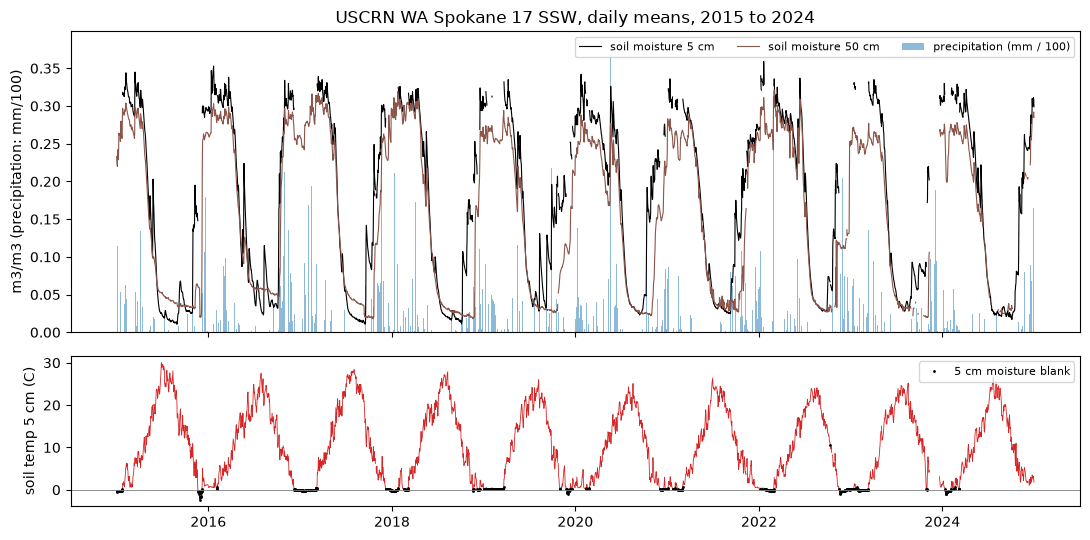

In [28]:
fig, (a1, a2) = plt.subplots(2, 1, figsize=(11, 5.5), sharex=True, height_ratios=[2, 1])
a1.bar(df.index, df["P_DAILY_CALC"] / 100, width=1, color="tab:blue", alpha=0.5, label="precipitation (mm / 100)")
a1.plot(sm5, color="k", lw=0.8, label="soil moisture 5 cm")
a1.plot(df["SOIL_MOISTURE_50_DAILY"], color="tab:brown", lw=0.8, label="soil moisture 50 cm")
a1.set_ylabel("m3/m3 (precipitation: mm/100)")
a1.legend(loc="upper right", fontsize=8, ncol=3)
a2.plot(df["SOIL_TEMP_5_DAILY"], color="tab:red", lw=0.6)
a2.plot(df.index[miss], df["SOIL_TEMP_5_DAILY"][miss], ".", color="k", ms=2, label="5 cm moisture blank")
a2.axhline(0, color="0.5", lw=0.6)
a2.set_ylabel("soil temp 5 cm (C)")
a2.legend(loc="upper right", fontsize=8)
a1.set_title("USCRN WA Spokane 17 SSW, daily means, 2015 to 2024")
plt.tight_layout()
plt.show()

**Your turn 3b.** Make `monthly`, the mean 5 cm soil moisture of each calendar month (a Series of 12 values, index 1 to 12), and `days_with_value`, the number of days with a value behind each of those means. Then make `sm5_monthly`, one mean per month of the record (a Series of 120 values), and plot it.

*Hint:* `sm5.groupby(sm5.index.month)` followed by `.mean()` or `.count()`; `sm5.resample("MS").mean()`, then `.plot()`.

In [29]:
# Your turn 3b: replace each None with your code
monthly = None
days_with_value = None
sm5_monthly = None
check.check_monthly(monthly, days_with_value, sm5_monthly)

not answered yet


correct. 4 months of the record have no 5 cm value at all and stay blank in sm5_monthly. Compare days_with_value in winter and in summer: frozen days are blank.


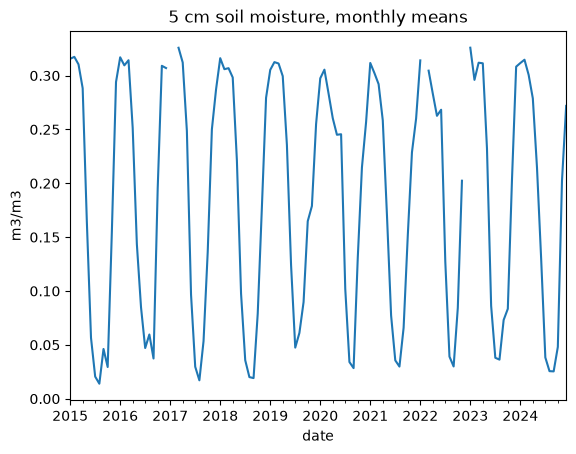

In [30]:
# Worked solution, open after you tried
ws_monthly = sm5.groupby(sm5.index.month).mean()
ws_days_with_value = sm5.groupby(sm5.index.month).count()
ws_sm5_monthly = sm5.resample("MS").mean()
ws_sm5_monthly.plot(ylabel="m3/m3", title="5 cm soil moisture, monthly means")
check.check_monthly(ws_monthly, ws_days_with_value, ws_sm5_monthly)

In [31]:
monthly = check.use_or_reference(monthly, check.reference_monthly, "monthly")
print("mean 5 cm soil moisture by month (m3/m3):", monthly.round(3).to_dict())
by_month = sm5.groupby(sm5.index.month)
print("days with a 5 cm value / calendar days, by month:",
      {m: f"{c}/{n}" for m, c, n in zip(by_month.count().index, by_month.count(), by_month.size())})
print("mean precipitation by month (mm/day, rain and melted snow):",
      df["P_DAILY_CALC"].groupby(df.index.month).mean().round(2).to_dict())
print("CRX_VN (datalogger program version) around late 2023:")
v = raw.loc["2023-11-01":"2023-12-31", "CRX_VN"]
print(v[v != v.shift()].to_string())

`monthly` is blank or not the expected shape. Using the reference result so you can continue; compare with yours.
mean 5 cm soil moisture by month (m3/m3): {1: 0.311, 2: 0.31, 3: 0.305, 4: 0.284, 5: 0.214, 6: 0.127, 7: 0.052, 8: 0.034, 9: 0.047, 10: 0.111, 11: 0.218, 12: 0.276}
days with a 5 cm value / calendar days, by month: {1: '143/310', 2: '120/283', 3: '253/310', 4: '300/300', 5: '310/310', 6: '300/300', 7: '310/310', 8: '310/310', 9: '299/300', 10: '301/310', 11: '241/300', 12: '155/310'}
mean precipitation by month (mm/day, rain and melted snow): {1: 1.98, 2: 1.65, 3: 1.22, 4: 1.06, 5: 1.27, 6: 0.76, 7: 0.17, 8: 0.24, 9: 0.54, 10: 1.5, 11: 2.11, 12: 2.52}
CRX_VN (datalogger program version) around late 2023:
date
2023-11-01    2.622
2023-11-12    2.424
2023-12-20    2.622


**Question 3.1.** What is the sampling interval, in days?

**Question 3.2.** How many days have no 5 cm soil moisture, and how long is the longest run of blank days?

**Question 3.3.** Most blanks fall in winter: why? What happened from 11 November to 20 December 2023, when every soil depth is blank but precipitation and air temperature are not? Use the gap table, the lower panel and `CRX_VN` (README field 3).

**Question 3.4.** Compare your Part 0 prediction with the monthly means: how close are the top months, and on how many days does each winter mean rest, since frozen days are blank? One sentence in `prediction_note`.

In [32]:
sampling_interval_days = ...
n_missing_sm5, longest_gap_days = ..., ...
winter_gaps_cause = ""
gap_2023_cause = ""
prediction_note = ""
check.check_interval(sampling_interval_days)
check.check_gaps(n_missing_sm5, longest_gap_days)
check.check_gap_causes(winter_gaps_cause, gap_2023_cause)
check.check_prediction_vs_data(predict_wettest_month, predict_driest_month)

not answered yet
not answered yet
not answered yet
not answered yet


In [33]:
# Worked solution, open after you tried
check.check_interval(1)
check.check_gaps(int(miss.sum()), int(gaps["days"].iloc[0]))
frozen_share = (df["SOIL_TEMP_5_DAILY"][miss] <= 1).mean()
print(f"{frozen_share:.0%} of blank 5 cm days have a 5 cm soil temperature at or below 1 C")
check.check_gap_causes("frozen soil: the probe cannot measure water in frozen soil, so USCRN leaves the day blank",
                       "a station outage of all soil probes: every depth is blank while rain and air temperature "
                       "continue, and the datalogger program version (CRX_VN) changes for the same weeks")
# Two cautions. The outage is an inference from the file: NCEI documents no outage for these dates. And a day is
# blank when hourly readings were flagged, so a day with a mean soil temperature of +0.5 C can still be blank;
# that is why some blank days above sit just above 0 C. CRX_VN also changes once mid-record, on 2018-09-23
# (2.422 to 2.622), a datalogger program change: look at whether anything in the soil series changes with it.
v = raw["CRX_VN"]
print(v[v != v.shift()].to_string())
check.check_prediction_vs_data(int(monthly.idxmax()), int(monthly.idxmin()))

correct. Every row is one day after the previous one; gaps are blank values, not missing rows.
correct. Now ask when the gaps happen.
91% of blank 5 cm days have a 5 cm soil temperature at or below 1 C
correct. Two causes, two different fixes: a frozen probe is a limit of the method; an outage is lost data.
date
2015-01-01    2.422
2018-09-23    2.622
2023-11-12    2.424
2023-12-20    2.622
correct. Your Part 0 prediction matches the monthly means. Months [1, 2, 3] all lie within 0.01 m3/m3 of the wettest: a late-winter plateau, not one wettest month. And those winter means rest only on the unfrozen days, because frozen days are blank.


```{admonition} If you are stuck
:class: tip
- The gap counts do not match: use `df` (codes replaced), not `raw`, and the 5 cm column only.
- Outage or frozen soil? Are the other depths and the soil temperature blank too, and how cold is the soil?
```

## Part 4. A 2D array: soil moisture by depth and time (about 12 min, if you have time)

The five probe columns form a 2D array, depth by time. Physics predicts its structure: rain wets the top first and moves down over days to weeks, deeper probes respond later and smoother, and summer root uptake dries even the deepest probe.

In [34]:
sm = xr.DataArray(np.vstack([df[f"SOIL_MOISTURE_{z}_DAILY"].values for z in DEPTHS]),
                  dims=("depth_cm", "time"), coords={"depth_cm": DEPTHS, "time": df.index.values},
                  name="soil_moisture", attrs={"units": "m3/m3", "source": "USCRN daily01, WA Spokane 17 SSW"})
print(sm)

<xarray.DataArray 'soil_moisture' (depth_cm: 5, time: 3653)> Size: 146kB
array([[  nan,   nan,   nan, ..., 0.311, 0.308, 0.299],
       [  nan,   nan,   nan, ..., 0.36 , 0.36 , 0.353],
       [0.266, 0.259, 0.254, ..., 0.321, 0.321, 0.315],
       [0.233, 0.227, 0.223, ..., 0.291, 0.292, 0.285],
       [0.204, 0.198, 0.193, ..., 0.242, 0.244, 0.237]], shape=(5, 3653))
Coordinates:
  * depth_cm  (depth_cm) int64 40B 5 10 20 50 100
  * time      (time) datetime64[us] 29kB 2015-01-01 2015-01-02 ... 2024-12-31
Attributes:
    units:    m3/m3
    source:   USCRN daily01, WA Spokane 17 SSW


**Your turn 4a.** Make `one_year`, the part of `sm` from 1 August 2021 to 31 July 2022 (a DataArray, depth by time), and `profile_mean`, its mean over time at each depth (a DataArray with one value per depth). Plot `profile_mean` against depth, surface at the top.

*Hint:* `sm.sel(time=slice(first_day, last_day))` with dates as `"YYYY-MM-DD"`, then `.mean("time")`; `.plot(y="depth_cm", yincrease=False)`.

In [35]:
# Your turn 4a: replace each None with your code
one_year = None
profile_mean = None
check.check_one_year(one_year, profile_mean)

not answered yet


correct. Each depth averages only the days it has a value: blank (frozen) days near the surface leave part of the winter out of the shallow means.


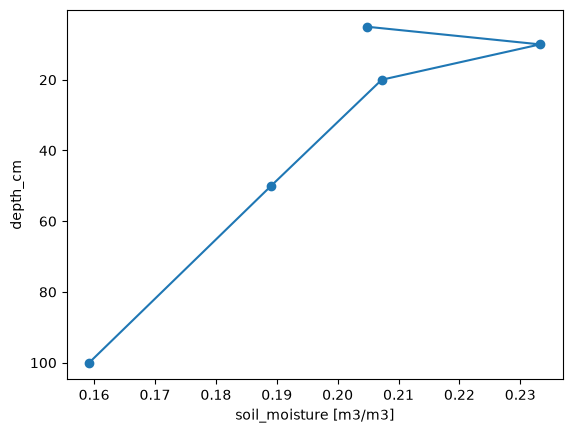

In [36]:
# Worked solution, open after you tried
ws_one_year = sm.sel(time=slice("2021-08-01", "2022-07-31"))
ws_profile_mean = ws_one_year.mean("time")
ws_profile_mean.plot(y="depth_cm", yincrease=False, marker="o")
check.check_one_year(ws_one_year, ws_profile_mean)

`one_year` is blank or not the expected shape. Using the reference result so you can continue; compare with yours.


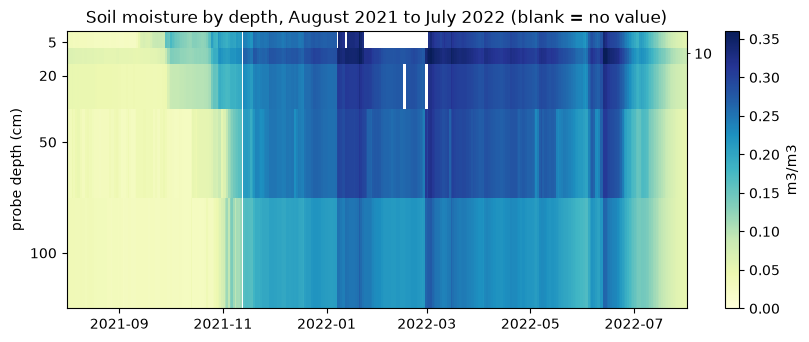

autumn 2021 arrival of the wetting front (first day 0.05 m3/m3 above the late-summer minimum):
5      2021-09-20
10     2021-09-29
20     2021-10-02
50     2021-10-29
100    2021-11-02


In [37]:
one_year = check.use_or_reference(one_year, check.reference_one_year, "one_year")
edges =[0, 7.5, 15, 35, 75, 125]                      # halfway between probes: a drawing choice, not data
fig, ax = plt.subplots(figsize=(10, 3.6))
t_edges = np.append(one_year["time"].values, one_year["time"].values[-1] + np.timedelta64(1, "D"))   # day boundaries
im = ax.pcolormesh(t_edges, edges, one_year.values, shading="flat", cmap="YlGnBu", vmin=0, vmax=0.36)
ax.set_yticks([5, 20, 50, 100])
ax.set_yticks([10], labels=["10"], minor=True)               # 10 cm labelled on the right: too close to 5 cm
ax.tick_params(axis="y", which="minor", left=False, right=True, labelleft=False, labelright=True)
ax.invert_yaxis()
ax.set(ylabel="probe depth (cm)", title="Soil moisture by depth, August 2021 to July 2022 (blank = no value)")
plt.colorbar(im, label="m3/m3", pad=0.05)
plt.show()
print("autumn 2021 arrival of the wetting front (first day 0.05 m3/m3 above the late-summer minimum):")
print(check.arrival_dates(2021).dt.date.to_string())

**Your turn 4b.** Make `change_by_depth`, the mean absolute day-to-day change of soil moisture at each depth over the whole record (a DataArray with one value per depth, in m³/m³). Show it.

*Hint:* `sm.diff("time")`, then `abs()`, then `.mean("time")`.

In [38]:
# Your turn 4b: replace each None with your code
change_by_depth = None
check.check_change_by_depth(change_by_depth)

not answered yet


In [39]:
# Worked solution, open after you tried
ws_change_by_depth = abs(sm.diff("time")).mean("time")
check.check_change_by_depth(ws_change_by_depth)
ws_change_by_depth.to_series().round(4)

correct. Compare the five values from top to bottom for Question 4.3.


depth_cm
5      0.0049
10     0.0041
20     0.0035
50     0.0034
100    0.0031
Name: soil_moisture, dtype: float64

**Question 4.1.** Is the depth axis evenly spaced? What is the time step?

**Question 4.2.** In autumn 2021, how many days did the wetting front take from 5 cm to 100 cm?

**Question 4.3.** Does the day-to-day change get smaller with every step down in depth?

Further: in 2018, 2019 and 2020 the 100 cm probe wets before the 50 cm one (`check.arrival_dates(2018)`). Give one physical and one instrumental explanation.

In [40]:
depth_spacing_uniform, time_step_days = ..., ...
delay_5_to_100_days = ...
change_decreases_with_depth = ...
check.check_axes(depth_spacing_uniform, time_step_days)
check.check_arrival(delay_5_to_100_days)
check.check_variability(change_decreases_with_depth)

not answered yet
not answered yet
not answered yet


In [41]:
# Worked solution, open after you tried
arr = check.arrival_dates(2021)
check.check_axes(False, 1)
check.check_arrival((arr[100] - arr[5]).days)
ch = [float(np.nanmean(np.abs(np.diff(sm.sel(depth_cm=z).values)))) for z in DEPTHS]
check.check_variability(all(a > b for a, b in zip(ch, ch[1:])))
print({y: (check.arrival_dates(y)[100] - check.arrival_dates(y)[5]).days for y in (2016, 2017, 2021)},
      "days from 5 to 100 cm, by autumn")
# The 2021 delay is one autumn: in 2016 the front took about a week, and in 2017 the 20, 50 and 100 cm probes all
# wetted on 22 October, the day of one large storm.
# 2018, 2019 and 2020 (100 cm before 50 cm): water can reach 100 cm through cracks and root channels faster than
# through the soil matrix around the 50 cm probes (preferential flow); or the 50 cm probes sit in a denser layer;
# or water ran down the backfilled hole dug to install the probes, or along their cables (an installation effect,
# not the soil); or one of the three 50 cm probes was flagged on those days, so the layer mean is an average of a
# different set of probes.

correct. Five probes at 5, 10, 20, 50 and 100 cm: an image drawn with equal rows would stretch the top.
correct. In 2021 the front took weeks to reach 1 m. Other autumns differ: 2016 took 8 days, and in 2017 (32 days from 5 cm) the 20, 50 and 100 cm probes wetted on the same day, during one storm. Run arrival_dates(2016) and arrival_dates(2017).
correct. Soil above a probe smooths the rain signal it receives.
{2016: 8, 2017: 32, 2021: 43} days from 5 to 100 cm, by autumn


```{admonition} If you are stuck
:class: tip
- `pcolormesh` complains about shapes: with `shading="flat"` each axis needs one more edge than cells (6 depth edges for 5 probes).
- The arrival delay is off: subtract the 5 cm date from the 100 cm date in `check.arrival_dates(2021)`.
```

## Part 5. A synthetic twin with planted problems (about 30 min)

(a) List possible problems. (b) Hunt for them. (c) Compute the response to rain three ways. (d) Write how each problem biased it. When you stop hunting, a `clean` that fixes only what you found is complete, and what you missed goes in (d). Two sentences are enough for (d).

`lab_s07_soil_synthetic.py` builds a **twin** of the Turnbull record: weather drawn from the real file's monthly statistics, soil from a five-layer water balance, and a known **truth**. The generator adds noise and **plants six problems** of ten kinds, placed by your NetID. Unlike the station, the twin blanks a depth when its daily mean soil temperature is below 0 °C, and its 50 and 100 cm layers sometimes wet in one step, which is not a planted spike. Compare the twin only with its own truth, and leave `twin.truth` closed until your findings are recorded.

```{admonition} 🔒 By hand
:class: attention
No AI tool for the judgment in this step: state what you expect before you run anything, decide with a physical reason, and read the result against your expectation ([1.8](../Chapter1-GettingStarted/1.8_ai_in_your_workflow.md)).
```

**(a) Before you look at your twin**, list the problems a soil probe, a precipitation gauge, a datalogger or a person converting the files could put in a daily table like this. Think through a year in the life of the station.

In [42]:
expected_problems = """
"""
check.check_expected_problems(expected_problems)

not answered yet


In [43]:
# Worked solution, open after you tried
check.check_expected_problems("""
Winter: the probe cannot see frozen water, so frozen days may come through as very dry instead of blank.
Electrical interference in thunderstorms gives one-day spikes. A failing probe or logger repeats its last value
(stuck). Slow drift as the probe ages or loses contact with the soil. A technician swaps two probes or two cables
during a visit, so the depths are exchanged. A load cell of the weighing gauge fails, or snow caps the opening,
and whoever assembles the table writes the missing days as 0 mm. When tables are joined, the precipitation total
is written on the day the gauge was read rather than the day it fell, so the rain lands one day late.
Converting the files: the -99 code left in as a number, days duplicated when files are joined, and a unit change
to percent.""")

You named 10 of the ten kinds this generator can plant.
correct. Now hunt for them in your twin.


In [44]:
twin = soil.make_twin(NETID)
twin_file = twin.write_csv(WORK / f"soil_twin_{NETID or 'class'}.csv")
obs = twin.observed                                       # what you were handed: one table, blank = missing
sm_cols = [f"sm_{z}cm" for z in DEPTHS]
print(f"seed {twin.seed}; {twin.n_planted} problems planted; file for Part 8: {twin_file}")
print("names to use in your findings:")
for k, v in PROBLEM_TYPES.items():
    print(f"  {k:22s} {v}")
obs.head(3)

seed 629; 6 problems planted; file for Part 8: s07_my_files/soil_twin_class.csv
names to use in your findings:
  spike                  isolated one-day jumps in a soil moisture column
  drift                  a slow, steady change in one probe that is not in the soil
  stuck                  a probe that repeats the same value day after day
  frozen_read_as_dry     frozen-soil days reported as very dry instead of left blank
  missing_code_left_in   a missing-value code written as a number
  gauge_outage_as_zero   days when the precipitation gauge failed, written as 0 mm
  rain_one_day_late      precipitation written one day after it fell
  probes_swapped         two probe depths exchanged after a maintenance visit
  duplicated_days        days that appear twice in the table
  units_percent          soil moisture written in percent instead of m3/m3


,date,t_max_c,t_min_c,t_mean_c,precip_mm,sm_5cm,sm_10cm,sm_20cm,sm_50cm,sm_100cm,st_5cm,st_10cm,st_20cm,st_50cm,st_100cm
0,2015-01-01,6.3,-10.8,-2.3,0.0,0.271,0.296,0.289,0.254,0.222,0.6,0.8,1.5,2.0,2.1
1,2015-01-02,2.0,-4.0,-1.0,6.7,0.275,0.296,0.291,0.253,0.224,0.3,0.5,1.5,2.1,2.2
2,2015-01-03,2.0,-9.8,-3.9,0.5,0.273,0.296,0.286,0.253,0.224,0.2,0.2,1.3,2.0,2.5


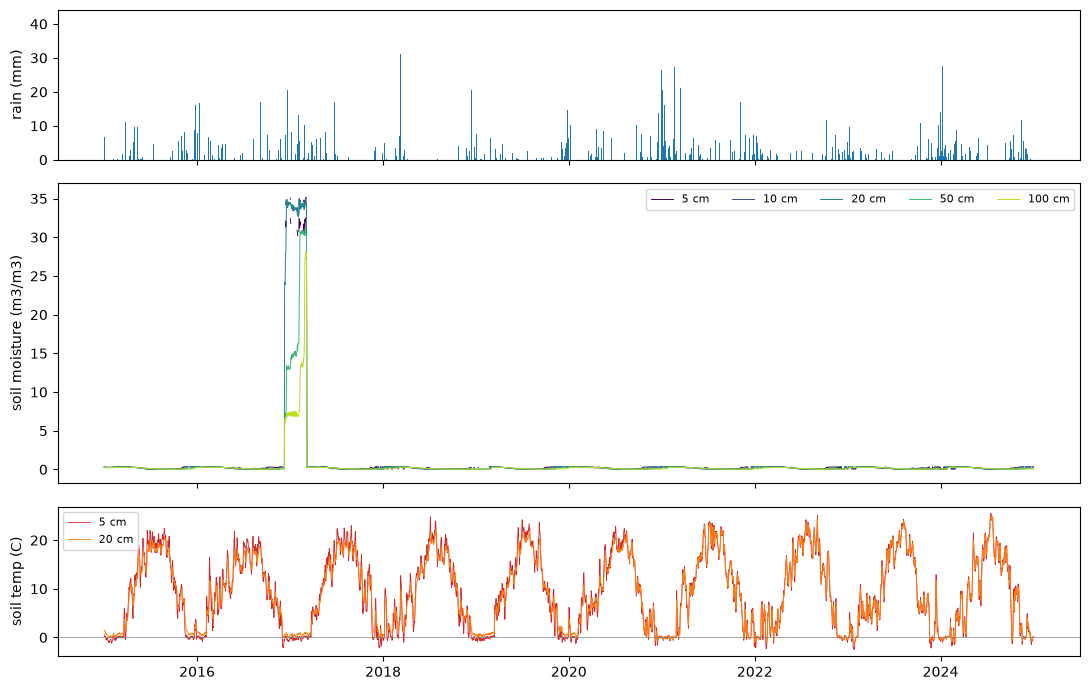

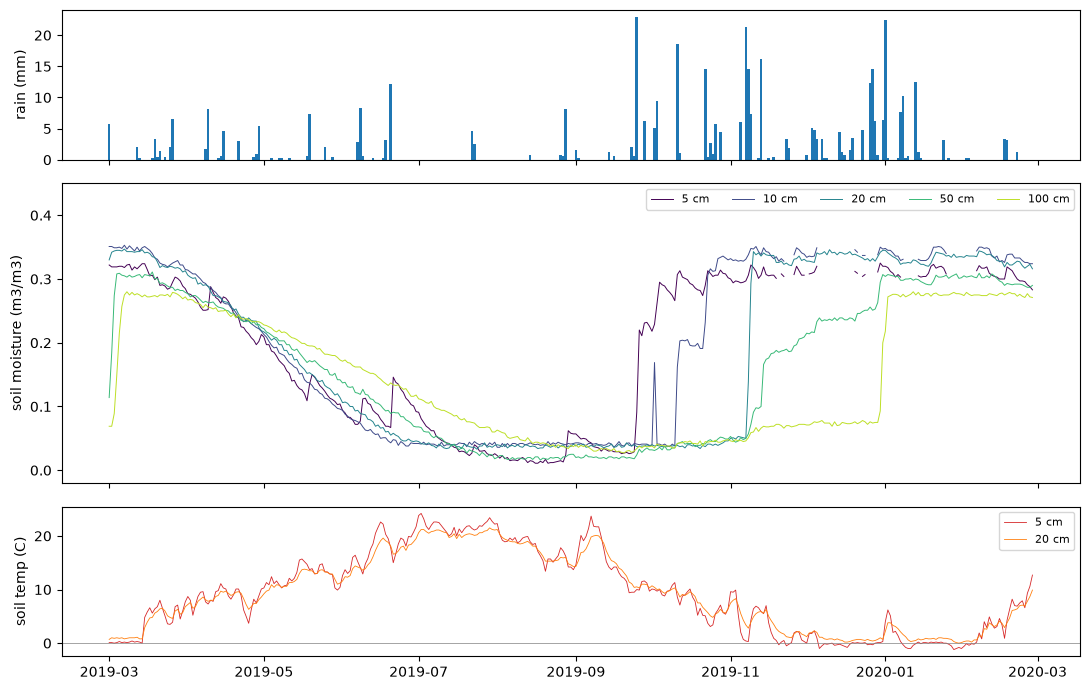

In [45]:
def plot_twin(table, start="2015-01-01", end="2024-12-31", sm_max=None):
    """Overview of a twin table: rain, the five soil moisture series and soil temperature at 5 and 20 cm.
    sm_max sets the top of the soil moisture axis, when one problem squeezes everything else flat."""
    t = table.assign(date=pd.to_datetime(table["date"])).set_index("date")
    t = t[(t.index >= start) & (t.index <= end)]                # rows kept in the order delivered
    fig, ax = plt.subplots(3, 1, figsize=(11, 7), sharex=True, height_ratios=[1, 2, 1])
    ax[0].bar(t.index, t["precip_mm"], width=1, color="tab:blue")
    ax[0].set_ylabel("rain (mm)")
    for z, c in zip(DEPTHS, plt.cm.viridis(np.linspace(0, 0.9, 5))):
        ax[1].plot(t[f"sm_{z}cm"], lw=0.7, color=c, label=f"{z} cm")
    ax[1].set_ylabel("soil moisture (m3/m3)")
    if sm_max is not None:
        ax[1].set_ylim(-0.02, sm_max)
    ax[1].legend(ncol=5, fontsize=8)
    ax[2].plot(t["st_5cm"], lw=0.6, color="tab:red", label="5 cm")
    ax[2].plot(t["st_20cm"], lw=0.6, color="tab:orange", label="20 cm")
    ax[2].axhline(0, color="0.5", lw=0.5)
    ax[2].set_ylabel("soil temp (C)")
    ax[2].legend(fontsize=8)
    plt.tight_layout()
    plt.show()


plot_twin(obs)
plot_twin(obs, "2019-03-01", "2020-02-28", sm_max=0.45)       # one year, axis limited to possible values

```{admonition} 🔒 By hand
:class: attention
No AI tool for the judgment in this step: state what you expect before you run anything, decide with a physical reason, and read the result against your expectation ([1.8](../Chapter1-GettingStarted/1.8_ai_in_your_workflow.md)).
```

**(b) Hunt.** A finding gives the kind (a name from the list), the column, the first and last dates, and why the values are physically implausible. Find at least three, then go on to (c); hunt for the rest if you have time. Your turn 5a and the checks after it find some problems for you; the rest need physics. Zoom with `plot_twin(obs, "2019-03-01", "2019-11-30")` and ask:

- What should the 5 cm probe report when the soil at 5 cm is below 0 °C?
- Which probe should follow air temperature more closely, 10 cm or 20 cm? Every year?
- Should the late-summer minimum at a depth climb year after year?
- When the soil wets up, did rain fall that day? In which year does it wet up the day *before* the rain?

**Your turn 5a.** Two checks that need no physics. Make `n_duplicated_dates`, the number of rows of `obs` whose date already appeared on an earlier row (an integer), and `out_of_range`, a Series with, for each soil moisture column in `sm_cols`, the number of values below 0 or above 1 m³/m³. Show `out_of_range`.

*Hint:* `.duplicated()` on `obs["date"]`, then `.sum()`; join the two comparisons with `|`, each one in parentheses: `(obs[sm_cols] < 0) | (...)`, then `.sum()`.

In [46]:
# Your turn 5a: replace each None with your code
n_duplicated_dates = None
out_of_range = None
check.check_first_checks(n_duplicated_dates, out_of_range, twin)

not answered yet


In [47]:
# Worked solution, open after you tried
ws_n_duplicated_dates = int(obs["date"].duplicated().sum())
ws_out_of_range = ((obs[sm_cols] < 0) | (obs[sm_cols] > 1)).sum()
check.check_first_checks(ws_n_duplicated_dates, ws_out_of_range, twin)
ws_out_of_range

correct. These checks need no physics. Each count above zero is a finding to record, with its dates.


sm_5cm      34
sm_10cm     33
sm_20cm     87
sm_50cm     87
sm_100cm    87
dtype: int64

In [48]:
print("rows:", len(obs), "  calendar days:", obs["date"].nunique())
tt = obs.assign(date=pd.to_datetime(obs["date"])).drop_duplicates("date").set_index("date")
jump = tt["sm_5cm"].where(tt["sm_5cm"].between(0, 1)).diff()      # possible values only
print("largest one-day rises at 5 cm (values between 0 and 1 only), with that day's rain:")
print(pd.DataFrame({"rise": jump, "rain_mm": tt["precip_mm"], "next day": jump.shift(-1)}).nlargest(6, "rise").round(3))
same = tt[sm_cols].diff().eq(0)
print("longest run of identical consecutive values, by column (days):",
      {c: int(same[c].groupby((~same[c]).cumsum()).sum().max()) + 1 for c in sm_cols})

rows: 3653   calendar days: 3653
largest one-day rises at 5 cm (values between 0 and 1 only), with that day's rain:
             rise  rain_mm  next day
date                                
2024-01-18  0.274      0.0     0.003
2024-02-28  0.272      0.6    -0.001
2023-12-08  0.269      0.0     0.003
2017-12-22  0.266      0.0     0.003
2023-11-30  0.262      0.9    -0.002
2018-02-08  0.261      0.0     0.005
longest run of identical consecutive values, by column (days): {'sm_5cm': 6, 'sm_10cm': 5, 'sm_20cm': 5, 'sm_50cm': 5, 'sm_100cm': 4}


In [49]:
# Record each finding. Example of the format (copy the line, do not keep the example):
#   dict(problem="spike", column="sm_10cm", start="2019-07-03", end="2019-07-03",
#        why="rises 0.1 m3/m3 with no rain and returns the next day; infiltrated water drains over days"),
findings = [
]
check_findings(findings, twin, show_missed=False)

not answered yet: add at least one finding to the list


When you have hunted for a while, set `show_missed=True` above and rerun to see which **kinds** you have not found (not where).

**(c) The derived quantity.** The response to rain is the rise in water content per amount of rain. `rain_response(table)` fits the day-to-day change at 5 cm against the day's precipitation (days with at least 2 mm, unfrozen soil) and returns the slope in m³/m³ per 10 mm. On cold days the gauge also catches snow that does not reach the soil that day, which lowers the response. Compute it on the truth, the table as delivered, and your cleaned table. First, three cleaning steps that need no dates and so fit every twin.

**Your turn 5b.** Make `basic`, the twin table `obs` with (1) each date kept once, (2) negative soil moisture blank in every `sm_cols` column, (3) `sm_5cm` blank on the days `st_5cm` is below 0 °C; then `r_basic`, the response to rain on `basic` (a float).

*Hint:* `.drop_duplicates("date")`; `.where(... >= 0)` on `basic[sm_cols]` only, assigned back to `basic[sm_cols]`; `basic.loc[condition, "sm_5cm"] = np.nan`; `rain_response(basic)[0]`.

In [50]:
# Your turn 5b: replace each None with your code
basic = None
r_basic = None
check.check_basic_clean(basic, r_basic, twin)

not answered yet


In [51]:
# Worked solution, open after you tried
ws_basic = obs.drop_duplicates("date")
ws_basic[sm_cols] = ws_basic[sm_cols].where(ws_basic[sm_cols] >= 0)       # -99 is the missing code
ws_basic.loc[ws_basic["st_5cm"] < 0, "sm_5cm"] = np.nan                   # the probe cannot see frozen water
ws_r_basic = rain_response(ws_basic)[0]
check.check_basic_clean(ws_basic, ws_r_basic, twin)

correct. Response to rain as delivered 0.0209, after these three steps 0.0209 m3/m3 per 10 mm. The steps need no dates, so they fit every twin; clean() below adds the steps that need your findings.
In your twin these steps do not move the response; the problems that do need dates.


Now the steps that need your findings. `clean` returns one row per day with the same columns, each line with its physical reason; you can start from your three lines above. The commented lines show patterns, not where your problems are.

In [52]:
def clean(table):
    """Your cleaning of the twin. Return one row per day, same columns."""
    t = table.copy()
    # One step per line, each with its reason. Patterns (START, END, COL are yours to fill):
    # t.loc[t["sm_5cm"] < 0, "sm_5cm"] = np.nan                                                    # -99 is the missing code
    # t["date"] = pd.to_datetime(t["date"]); t = t.drop_duplicates("date").set_index("date").asfreq("D")  # a day happens once
    # t.loc[START:END, ["sm_10cm", "sm_20cm"]] = t.loc[START:END, ["sm_20cm", "sm_10cm"]].values      # exchange depths back
    # t.loc[START:END, COL] = np.nan                                                                 # no true value to recover
    # t = t.reset_index().assign(date=lambda x: x["date"].dt.strftime("%Y-%m-%d"))                   # after set_index above
    return t


r_truth = ...           # rain_response(twin.truth)[0]
r_contaminated = ...    # rain_response(twin.observed)[0]
r_cleaned = ...         # rain_response(clean(twin.observed))[0]
check.check_three_values(r_truth, r_contaminated, r_cleaned, twin, clean)

not answered yet


**(d) Reflect.** For each problem you found: did it bias the response, in which direction, and why (which column and which days does the response use)? Which problems did cleaning undo, and which can no cleaning undo? Use the names above.

In [53]:
reflection_part5 = """
"""
check.check_reflection(reflection_part5)

not answered yet


In [54]:
# Worked solution, open after you tried
# The hunt below uses only physical checks; it is run on the class twin (NetID "class"), so your dates differ.
ws_twin = soil.make_twin("class")
SMC = [f"sm_{z}cm" for z in DEPTHS]


def runs(mask, join=0):
    """(first, last) positions of each run of True values; runs separated by `join` days or fewer are merged."""
    m = np.r_[False, np.asarray(mask, bool), False]
    d = np.diff(m.astype(int))
    out = []
    for a, b in zip(np.where(d == 1)[0], np.where(d == -1)[0] - 1):
        if out and a - out[-1][1] - 1 <= join:
            out[-1] = (out[-1][0], b)
        else:
            out.append((a, b))
    return out


def hunt(table):
    t = table.copy()
    t["date"] = pd.to_datetime(t["date"])
    f = []
    dup = t["date"].duplicated(keep=False)
    if dup.any():
        d = t.loc[dup, "date"]
        f.append(dict(problem="duplicated_days", column="date", start=str(d.min().date()), end=str(d.max().date()),
                      why="the same date appears on two rows; a day happens once"))
    t = t.drop_duplicates("date").set_index("date").asfreq("D")
    day = lambda i: str(t.index[i].date())
    for c in SMC:                                                   # impossible water contents
        for problem, mask, why in (("missing_code_left_in", t[c] < 0, "negative water content; -99 is the missing code"),
                                   ("units_percent", t[c] > 1, "above 1 m3/m3; values 100 times too large")):
            f += [dict(problem=problem, column=c, start=day(a), end=day(b), why=why) for a, b in runs(mask.values, 30)]
    ok = t[SMC].where((t[SMC] >= 0) & (t[SMC] <= 1))
    for c, tc in (("sm_5cm", "st_5cm"), ("sm_10cm", "st_10cm")):     # values on frozen days
        f += [dict(problem="frozen_read_as_dry", column=c, start=day(a), end=day(b),
                   why="reported while the soil is below 0 C, as dry as August with nothing evaporating")
              for a, b in runs((ok[c].notna() & (t[tc] < -0.2)).values, 60) if b - a >= 2]
        ok.loc[t[tc] < 0, c] = np.nan
    thawed = t["st_5cm"].rolling(7, center=True, min_periods=1).min() > 1.0
    for c in ("sm_5cm", "sm_10cm"):                                 # up and straight back down
        d1 = ok[c].diff()
        for d in t.index[((d1 > 0.05) & (d1.shift(-1) < -0.7 * d1) & thawed).values]:
            f.append(dict(problem="spike", column=c, start=str(d.date()), end=str(d.date()),
                          why="rises and falls back within a day; infiltrated water drains over days"))
    for c in SMC:                                                   # identical values for a week
        same = ok[c].diff().eq(0)
        f += [dict(problem="stuck", column=c, start=day(a - 1), end=day(b),
                   why="identical to 0.001 m3/m3 for a week or more, through rain and drying")
              for a, b in runs(same.values) if b - a + 1 >= 6]
    d10 = t["st_10cm"].diff().abs().rolling(60, center=True).mean()  # the shallower probe must vary more
    d20 = t["st_20cm"].diff().abs().rolling(60, center=True).mean()
    rr = [r for r in runs((d20 > 1.1 * d10).values) if r[1] - r[0] > 200]
    if rr:
        f.append(dict(problem="probes_swapped", column="sm_10cm", start=day(rr[0][0] + 30), end=day(len(t) - 1),
                      why="from here the 20 cm temperature varies more than the 10 cm one: depths exchanged"))
    for c in SMC[2:]:                                               # a dry-season floor that climbs
        floor = ok[c][ok.index.month.isin([8, 9, 10])].groupby(lambda d: d.year).min()
        rise = floor.diff()
        if (rise.tail(4) > 0.006).sum() >= 3:
            f.append(dict(problem="drift", column=c, start=f"{int(rise[rise > 0.006].index[0]) - 1}-09-01",
                          end=day(len(t) - 1), why="late-summer minimum rises every year at this depth only"))
    p = t["precip_mm"]
    for a, b in runs((p == 0).values):                              # no rain while the soil wets up
        if b - a + 1 >= 20 and (ok["sm_5cm"].iloc[a:b + 1].diff() > 0.02).sum() >= 2:
            f.append(dict(problem="gauge_outage_as_zero", column="precip_mm", start=day(a), end=day(b),
                          why="the 5 cm soil wets up several times while the gauge records nothing"))
    ch = ok["sm_5cm"].diff()
    before = {}                                                     # does the soil wet up the day before the rain?
    thawed3 = (t["st_5cm"].rolling(3).min() > 0.5).values        # three thawed days: keeps freeze and thaw
    for y in sorted(set(t.index.year)):                             # days, where frozen readings jump, out
        sel = (t.index.year == y) & thawed3
        x, cm1 = p[sel], ch.shift(1)[sel]
        g = x.notna() & cm1.notna()
        before[y] = np.corrcoef(x[g], cm1[g])[0, 1]
    typical = np.median(list(before.values()))
    for y, r in before.items():
        if r > 0.25 and r > typical + 0.2:
            f.append(dict(problem="rain_one_day_late", column="precip_mm", start=f"{y}-01-01", end=f"{y}-12-31",
                          why=f"in {y} the soil wets up the day before the recorded rain (r = {r:.2f}, other years "
                              f"about {typical:.2f}); water cannot arrive before it falls"))
    return f


def clean_ws(table):
    t = table.copy()
    t["date"] = pd.to_datetime(t["date"])
    t = t.drop_duplicates("date").set_index("date").asfreq("D")             # one row per day
    for fd in hunt(table):
        a, b, c, k = pd.Timestamp(fd["start"]), pd.Timestamp(fd["end"]), fd["column"], fd["problem"]
        span = (t.index >= a) & (t.index <= b)
        if k in ("spike", "stuck"):
            t.loc[span, c] = np.nan                                          # no true value to recover
        elif k == "missing_code_left_in":
            t.loc[span & (t[c] < 0), c] = np.nan                             # the code means "no value"
        elif k == "frozen_read_as_dry":
            t.loc[span & (t["st_" + c[3:]] <= 0), c] = np.nan                # blank where frozen, as USCRN does
        elif k == "units_percent":
            t.loc[span & (t[c] > 1), c] = t.loc[span & (t[c] > 1), c] / 100  # percent back to m3/m3
        elif k == "probes_swapped":
            for x, y in (("sm_10cm", "sm_20cm"), ("st_10cm", "st_20cm")):
                t.loc[a:b, [x, y]] = t.loc[a:b, [y, x]].values               # exchange back
        elif k == "gauge_outage_as_zero":
            t.loc[a:b, "precip_mm"] = np.nan                                 # unknown, not zero
        elif k == "rain_one_day_late":
            t.loc[a - pd.Timedelta(days=1):b - pd.Timedelta(days=1), "precip_mm"] = t.loc[a:b, "precip_mm"].values
        # drift is left in place: without a reference measurement we do not know the true floor
    return t.reset_index().assign(date=lambda x: x["date"].dt.strftime("%Y-%m-%d"))


ws_findings = hunt(ws_twin.observed)
print(pd.DataFrame(ws_findings)[["problem", "column", "start", "end"]].to_string())
check_findings(ws_findings, ws_twin, show_missed=True)
ws_r = {"truth": rain_response(ws_twin.truth)[0], "as delivered": rain_response(ws_twin.observed)[0],
        "after cleaning": rain_response(clean_ws(ws_twin.observed))[0]}
print({k: round(v, 4) for k, v in ws_r.items()}, "m3/m3 per 10 mm")
check.check_three_values(*ws_r.values(), ws_twin, clean_ws)
print("median drydown time at 5 cm (days), truth / delivered / cleaned:",
      [round(soil.drydown_timescale(x)[0], 1) for x in (ws_twin.truth, ws_twin.observed, clean_ws(ws_twin.observed))])

                 problem     column       start         end
0          units_percent     sm_5cm  2016-12-13  2017-03-06
1          units_percent    sm_10cm  2016-12-13  2017-03-06
2          units_percent    sm_20cm  2016-12-10  2017-03-06
3          units_percent    sm_50cm  2016-12-10  2017-03-06
4          units_percent   sm_100cm  2016-12-10  2017-03-06
5     frozen_read_as_dry     sm_5cm  2017-11-23  2018-03-24
6     frozen_read_as_dry     sm_5cm  2022-12-09  2023-01-31
7     frozen_read_as_dry     sm_5cm  2023-11-19  2024-02-27
8     frozen_read_as_dry    sm_10cm  2017-12-11  2018-03-24
9                  spike    sm_10cm  2015-06-15  2015-06-15
10                 spike    sm_10cm  2016-08-14  2016-08-14
11                 spike    sm_10cm  2016-10-04  2016-10-04
12                 spike    sm_10cm  2019-10-02  2019-10-02
13        probes_swapped    sm_10cm  2020-09-18  2024-12-31
14  gauge_outage_as_zero  precip_mm  2016-04-24  2016-05-26
15     rain_one_day_late  precip_mm  202

{'truth': 0.016, 'as delivered': 0.0209, 'after cleaning': 0.0165} m3/m3 per 10 mm
correct. Off from the truth: as delivered 30%, cleaned 3%.
median drydown time at 5 cm (days), truth / delivered / cleaned: [28.5, 27.4, 27.4]


The worked solution also computes the median e-folding time of drying after warm-season storms (`soil.drydown_timescale`). It hardly moves: a median over some forty drydowns ignores the few a stuck probe or a spike corrupts, which still carry the problem.

```{admonition} If you are stuck
:class: tip
- A finding matches nothing: check the name, the column, and that the `YYYY-MM-DD` dates overlap the problem without spanning far beyond it.
- A problem that comes back each winter needs one finding per winter.
- Your cleaned value is still far from the truth: only problems in `sm_5cm`, `st_5cm` or `precip_mm` can move the response.
```

## Part 6. Correlations on the real data (about 10 min, plus 6 if you have time)

```{admonition} 🔒 By hand
:class: attention
No AI tool for the judgment in this step: state what you expect before you run anything, decide with a physical reason, and read the result against your expectation ([1.8](../Chapter1-GettingStarted/1.8_ai_in_your_workflow.md)).
```

**Question 6.1.** Before computing: what sign (`"+"` or `"-"`) do you expect for the correlation of a day's precipitation with that day's change in 5 cm soil moisture? For daily mean air temperature with 5 cm soil moisture?

In [55]:
rain_vs_change_sign = ""
temp_vs_moisture_sign = ""
check.check_signs(rain_vs_change_sign, temp_vs_moisture_sign)

not answered yet


,n_days,pearson,spearman
lag_days,,,
-2,2985,0.065,0.032
-1,2986,0.100,0.069
0,2989,0.577,0.337
1,2989,0.344,0.264
2,2987,-0.039,-0.019
3,2987,-0.022,-0.051


lag 0 uses 2989 unfrozen days; 73% of them had no precipitation


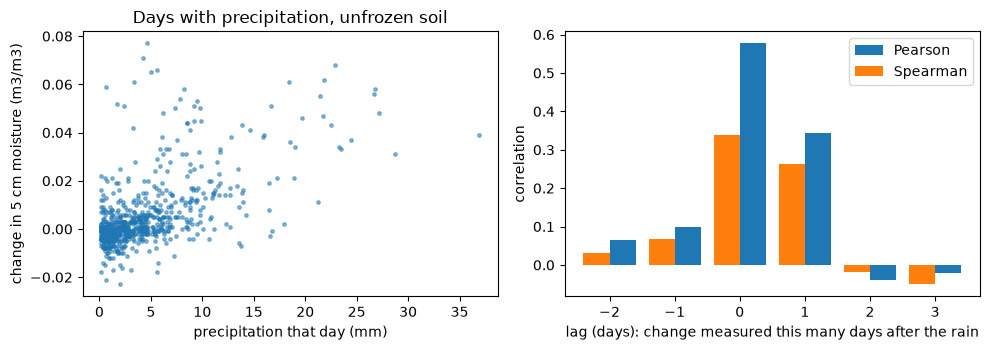

In [56]:
lags = check.lag_table(df)                 # every unfrozen day, with or without precipitation
display(lags.round(3))
day0 = (df["SOIL_TEMP_5_DAILY"] > 0) & (df["SOIL_TEMP_5_DAILY"].shift(1) > 0) & df["P_DAILY_CALC"].notna()     & df["SOIL_MOISTURE_5_DAILY"].diff().notna()
print(f"lag 0 uses {int(day0.sum())} unfrozen days; {(df['P_DAILY_CALC'][day0] == 0).mean():.0%} of them had no precipitation")
change = df["SOIL_MOISTURE_5_DAILY"].diff()
use = (df["P_DAILY_CALC"] > 0) & (df["SOIL_TEMP_5_DAILY"] > 0) & change.notna()
fig, ax = plt.subplots(1, 2, figsize=(10, 3.6))
ax[0].scatter(df["P_DAILY_CALC"][use], change[use], s=6, alpha=0.5)
ax[0].set(xlabel="precipitation that day (mm)", ylabel="change in 5 cm moisture (m3/m3)", title="Days with precipitation, unfrozen soil")
ax[1].bar(lags.index, lags["pearson"], width=0.4, label="Pearson", align="edge")
ax[1].bar(lags.index - 0.4, lags["spearman"], width=0.4, label="Spearman", align="edge")
ax[1].set(xlabel="lag (days): change measured this many days after the rain", ylabel="correlation")
ax[1].legend()
plt.tight_layout()
plt.show()

**Question 6.2.** At which lag is Pearson largest, and which is second? Why is the second non-zero for means over an LST day? Why is Spearman lower than Pearson: how does a rank correlation treat the many tied zeros (days without precipitation), and what do the few large storms do to Pearson?

In [57]:
lag_of_max, second_lag = ..., ...
check.check_lag(lag_of_max, second_lag)

not answered yet


In [58]:
# Worked solution, open after you tried
check.check_signs("+", "-")
order = lags["pearson"].sort_values(ascending=False).index
check.check_lag(order[0], order[1])
# What the correlations say: rain and the same-day soil change go together, and part of the response lands on the
# next day because the daily value is a mean over the day. What they do not say: the raw temperature correlation
# is mostly the season (Your turn 6a); a correlation does not give the mechanism (warm days dry the soil, or dry
# soil warms the air?), and frozen days are left out of every number here, so winter is not represented.

correct. Recorded. Compare it with the correlations below.
correct. Rain that falls late in a Local Standard Time day shows up in the next day's average.


**The trap: a shared seasonal cycle.** Warm months are dry months at Turnbull, so temperature and soil moisture correlate across the year even if a warm day does nothing to the soil that day. Remove the mean seasonal cycle from both (anomaly: each day minus the smoothed ten-year mean of that calendar day) and correlate again. Daily anomalies persist, so for lag-1 autocorrelations r1 and r2 the effective number of independent pairs is n_eff = n (1 − r1 r2) / (1 + r1 r2) (Bretherton et al., 1999, doi:10.1175/1520-0442(1999)012<1990:TENOSD>2.0.CO;2).

In [59]:
def anomaly(x):
    """Each day minus the mean of its calendar day over the ten years, smoothed over 31 days."""
    doy = x.index.dayofyear
    clim = x.groupby(doy).mean()
    clim = pd.concat([clim.iloc[-15:], clim, clim.iloc[:15]]).rolling(31, center=True).mean().iloc[15:-15]
    return x - clim.reindex(doy).values


T, S = df["T_DAILY_MEAN"], df["SOIL_MOISTURE_5_DAILY"]      # daily mean air temperature, 5 cm soil moisture

**Your turn 6a (Question 6.3).** Make `Ta` and `Sa`, the anomalies of `T` and `S` from `anomaly()`, and two Pearson correlations as floats: `r_raw` between `T` and `S`, and `r_anomaly` between `Ta` and `Sa`.

*Hint:* `T.corr(S)` gives Pearson r and skips the days on which either value is blank.

In [60]:
# Your turn 6a (Question 6.3): replace each None with your code
Ta = None
Sa = None
r_raw = None
r_anomaly = None
check.check_seasonal_trap(r_raw, r_anomaly)

not answered yet


In [61]:
# Worked solution, open after you tried
ws_Ta = anomaly(T)
ws_Sa = anomaly(S)
ws_r_raw = T.corr(S)
ws_r_anomaly = ws_Ta.corr(ws_Sa)
check.check_seasonal_trap(ws_r_raw, ws_r_anomaly)

correct. Most of the raw correlation is the shared seasonal cycle, not day-to-day coupling.


`Ta` is blank or not the expected shape. Using the reference result so you can continue; compare with yours.
`Sa` is blank or not the expected shape. Using the reference result so you can continue; compare with yours.
`r_anomaly` is blank or not the expected shape. Using the reference result so you can continue; compare with yours.


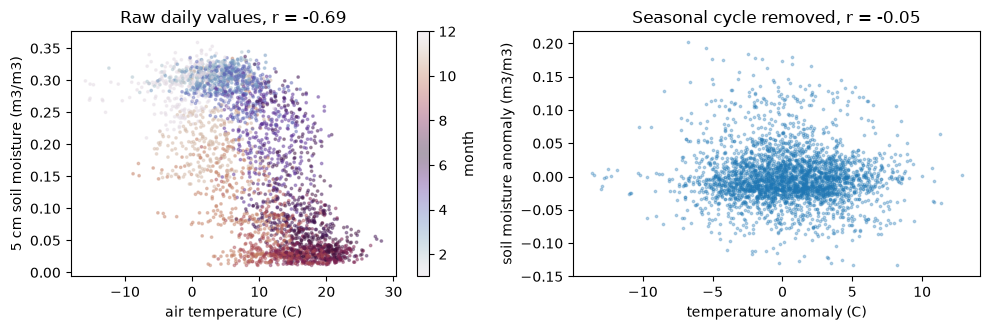

In [62]:
Ta = check.use_or_reference(Ta, check.reference_Ta, "Ta")
Sa = check.use_or_reference(Sa, check.reference_Sa, "Sa")
r_anomaly = check.use_or_reference(r_anomaly, check.reference_r_anomaly, "r_anomaly")
both = T.notna() & S.notna()
both_a = Ta.notna() & Sa.notna()
r_raw_true, r_anom_true = stats.pearsonr(T[both], S[both])[0], stats.pearsonr(Ta[both_a], Sa[both_a])[0]
fig, ax = plt.subplots(1, 2, figsize=(10, 3.4))
sc = ax[0].scatter(T[both], S[both], s=3, alpha=0.4, c=T[both].index.month, cmap="twilight")
plt.colorbar(sc, ax=ax[0], label="month")
ax[0].set(xlabel="air temperature (C)", ylabel="5 cm soil moisture (m3/m3)", title=f"Raw daily values, r = {r_raw_true:.2f}")
ax[1].scatter(Ta[both_a], Sa[both_a], s=3, alpha=0.3)
ax[1].set(xlabel="temperature anomaly (C)", ylabel="soil moisture anomaly (m3/m3)",
          title=f"Seasonal cycle removed, r = {r_anom_true:.2f}")
plt.tight_layout()
plt.show()

**Your turn 6b (Question 6.4, if you have time).** Does the anomaly correlation differ from zero? Make `n_both`, the number of days on which both anomalies have a value (an integer); `r1` and `r2`, the lag-1 autocorrelations of `Ta` and `Sa`; `n_eff` from the formula above; and `anomaly_r_differs_from_zero`, True when |r_anomaly| (that is, `abs(Ta.corr(Sa))`) is above 2/√n_eff (about the 95% level).

*Hint:* `(Ta.notna() & Sa.notna()).sum()`, `Ta.autocorr(1)`, `abs()` and `np.sqrt()`.

In [63]:
# Your turn 6b (Question 6.4, if you have time): replace each None with your code
n_both = None
r1, r2 = None, None
n_eff = None
anomaly_r_differs_from_zero = None
check.check_neff(n_eff)
check.check_significance(anomaly_r_differs_from_zero)

not answered yet
not answered yet


In [64]:
# Worked solution, open after you tried
ws_n_both = int((Ta.notna() & Sa.notna()).sum())
ws_r1, ws_r2 = Ta.autocorr(1), Sa.autocorr(1)
ws_n_eff = ws_n_both * (1 - ws_r1 * ws_r2) / (1 + ws_r1 * ws_r2)
ws_anomaly_r_differs_from_zero = abs(Ta.corr(Sa)) > 2 / np.sqrt(ws_n_eff)
check.check_neff(ws_n_eff)
check.check_significance(ws_anomaly_r_differs_from_zero)

correct. Thousands of days, but only a few hundred independent pieces of information.


correct. |r| = 0.05 against 2/sqrt(n_eff) = 0.09: once the season is removed, a warm day says nothing about that day's soil moisture.


```{admonition} If you are stuck
:class: tip
- `lag_table` returns NaN: run Part 2 first, so `df` exists.
- n_eff rejected: n counts only the days on which both anomalies have a value.
```

## Part 7. From data to a learning problem (about 12 min, plus 6 if you have time)

```{admonition} 🔒 By hand
:class: attention
No AI tool for the judgment in this step: state what you expect before you run anything, decide with a physical reason, and read the result against your expectation ([1.8](../Chapter1-GettingStarted/1.8_ai_in_your_workflow.md)).
```

**Question 7.1.** Write the chain from the raw file to a table a model could learn from, in order, each step with its reason: rows, depths and periods kept; what you remove and what you keep as a real extreme; frozen days; resampling; anomalies or not; a training, validation and test split with no leak; where balancing goes.

In [65]:
pipeline_steps = [
    "",
]
check.check_pipeline(pipeline_steps)

not answered yet


**Question 7.2.** Which machine learning (ML) task fits the guiding question, and what exactly is the target? For example:

- **regression:** tomorrow's change in 5 cm soil moisture, from today's soil moisture and the precipitation observed up to today (add tomorrow's precipitation only as a forecast, and say so);
- **classification of dry spells:** whether the soil at 20 cm is in the driest tenth of the training years' days.

In [66]:
ml_task = ""          # regression, classification, forecasting, detection or clustering
ml_target = ""
check.check_task(ml_task, ml_target)

not answered yet


In [67]:
# Split by whole years, in time order: neighbouring days share weather, so a random split would leak.
split = pd.Series(np.select([df.index.year <= 2020, df.index.year <= 2022], ["train", "validation"], "test"), index=df.index)
print("days per split:", split.value_counts().to_dict())

days per split: {'train': 2192, 'test': 731, 'validation': 730}


**Your turn 7a.** The dry-spell target. Make `s20`, the 20 cm soil moisture column of `df`; `threshold`, its 10th percentile over the **training** days only (a float); `dry`, a Series that is 1.0 on days below the threshold, 0.0 on other days and blank where `s20` is blank; and `dry_share`, the share of dry days in each split (a Series indexed by split name).

*Hint:* `.quantile(0.10)` on `s20[split == "train"]`; `.astype(float)` then `.where(s20.notna())`; `.groupby(split).mean()`.

In [68]:
# Your turn 7a: replace each None with your code
s20 = None
threshold = None
dry = None
dry_share = None
check.check_dry_target(threshold, dry, dry_share)

not answered yet


In [69]:
# Worked solution, open after you tried
ws_s20 = df["SOIL_MOISTURE_20_DAILY"]
ws_threshold = ws_s20[split == "train"].quantile(0.10)        # defined on the training years only
ws_dry = (ws_s20 < ws_threshold).astype(float).where(ws_s20.notna())
ws_dry_share = ws_dry.groupby(split).mean()
check.check_dry_target(ws_threshold, ws_dry, ws_dry_share)

correct. The dry share is not the same in the three splits. Question 7.3 asks for the training one.


**Your turn 7b (if you have time).** The regression target. Make `y_reg`, tomorrow's 5 cm soil moisture minus today's, on today's row (a Series with one value per day), and print how many days rise by 0.02 m³/m³ or more and the skewness of `y_reg`.

*Hint:* `.shift(-1)` moves tomorrow's value onto today's row; `.skew()`.

In [70]:
# Your turn 7b (if you have time): replace each None with your code
y_reg = None
# print(...)
check.check_reg_target(y_reg)

not answered yet


In [71]:
# Worked solution, open after you tried
ws_y_reg = df["SOIL_MOISTURE_5_DAILY"].shift(-1) - df["SOIL_MOISTURE_5_DAILY"]
print("days rising by 0.02 m3/m3 or more:", int((ws_y_reg >= 0.02).sum()), "  skewness:", round(ws_y_reg.skew(), 1))
check.check_reg_target(ws_y_reg)

days rising by 0.02 m3/m3 or more: 94   skewness: 3.8
correct. Most days barely change and a few storms make large rises: skewness 3.8.


`threshold` is blank or not the expected shape. Using the reference result so you can continue; compare with yours.
`dry` is blank or not the expected shape. Using the reference result so you can continue; compare with yours.
`dry_share` is blank or not the expected shape. Using the reference result so you can continue; compare with yours.
`y_reg` is blank or not the expected shape. Using the reference result so you can continue; compare with yours.
dry class: 20 cm soil moisture below 0.052 m3/m3 (10th percentile of 2015 to 2020)


,days with a value,dry-class share,regression target: share of days rising by 0.02 or more
train,2158,0.089,0.036
validation,717,0.170,0.025
test,666,0.258,0.023


dry-class share by month (all years): {1: 0.0, 2: 0.0, 3: 0.0, 4: 0.0, 5: 0.0, 6: 0.0, 7: 0.02, 8: 0.33, 9: 0.71, 10: 0.51, 11: 0.04, 12: 0.0}
days with a 20 cm value, by year: {2015: 361, 2016: 365, 2017: 345, 2018: 359, 2019: 362, 2020: 366, 2021: 364, 2022: 353, 2023: 322, 2024: 344}
dry days, by year: {2015: 31, 2016: 0, 2017: 42, 2018: 71, 2019: 0, 2020: 49, 2021: 65, 2022: 57, 2023: 93, 2024: 79}
response when yesterday's 5 cm moisture is 0 to 0.1 m3/m3: 0.025 m3/m3 per 10 mm (80 days)
response when yesterday's 5 cm moisture is 0.1 to 0.2 m3/m3: 0.017 m3/m3 per 10 mm (80 days)
response when yesterday's 5 cm moisture is 0.2 to 0.28 m3/m3: 0.019 m3/m3 per 10 mm (114 days)
response when yesterday's 5 cm moisture is 0.28 to 1 m3/m3: 0.015 m3/m3 per 10 mm (176 days)


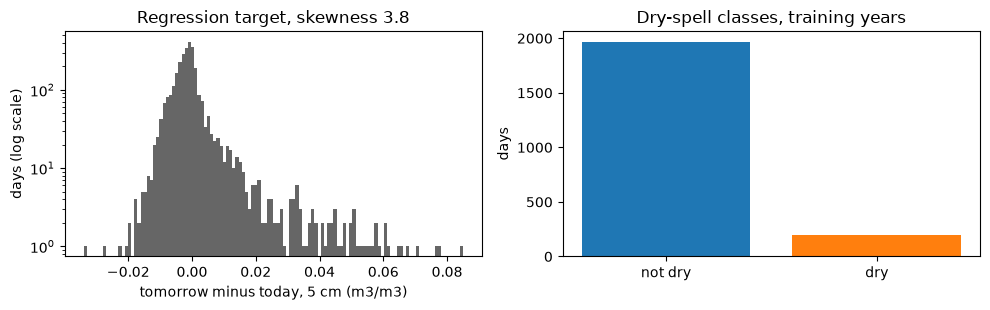

In [72]:
threshold = check.use_or_reference(threshold, check.reference_threshold, "threshold")
dry = check.use_or_reference(dry, check.reference_dry, "dry")
dry_share = check.use_or_reference(dry_share, check.reference_dry_share, "dry_share")
y_reg = check.use_or_reference(y_reg, check.reference_y_reg, "y_reg")
summary = pd.DataFrame({
    "days with a value": dry.groupby(split).count(),
    "dry-class share": dry.groupby(split).mean().round(3),
    "regression target: share of days rising by 0.02 or more": (y_reg >= 0.02).where(y_reg.notna()).groupby(split).mean().round(3),
}).loc[["train", "validation", "test"]]
print(f"dry class: 20 cm soil moisture below {threshold:.3f} m3/m3 (10th percentile of 2015 to 2020)")
display(summary)
print("dry-class share by month (all years):", dry.groupby(df.index.month).mean().round(2).to_dict())
print("days with a 20 cm value, by year:", df["SOIL_MOISTURE_20_DAILY"].groupby(df.index.year).count().to_dict())
print("dry days, by year:", dry.groupby(df.index.year).sum().astype(int).to_dict())
# Does the response to precipitation depend on how wet the soil already is? (an input for the regression)
sm_prev, dsm = df["SOIL_MOISTURE_5_DAILY"].shift(1), df["SOIL_MOISTURE_5_DAILY"].diff()
rain_day = (df["P_DAILY_CALC"] >= 2) & (df["SOIL_TEMP_5_DAILY"] > 0) & (df["SOIL_TEMP_5_DAILY"].shift(1) > 0) & dsm.notna()
for lo, hi in [(0, 0.1), (0.1, 0.2), (0.2, 0.28), (0.28, 1)]:
    u = rain_day & (sm_prev >= lo) & (sm_prev < hi)
    print(f"response when yesterday's 5 cm moisture is {lo} to {hi} m3/m3: "
          f"{np.polyfit(df['P_DAILY_CALC'][u], dsm[u], 1)[0] * 10:.3f} m3/m3 per 10 mm ({int(u.sum())} days)")
fig, ax = plt.subplots(1, 2, figsize=(10, 3.2))
ax[0].hist(y_reg.dropna(), bins=120, color="0.4")
ax[0].set(yscale="log", xlabel="tomorrow minus today, 5 cm (m3/m3)", ylabel="days (log scale)",
          title=f"Regression target, skewness {y_reg.skew():.1f}")
ax[1].bar(["not dry", "dry"], dry[split == "train"].value_counts().sort_index().values, color=["tab:blue", "tab:orange"])
ax[1].set(title="Dry-spell classes, training years", ylabel="days")
plt.tight_layout()
plt.show()

In [73]:
# What balancing does, on the training years only.
y_train = dry[(split == "train") & dry.notna()].astype(bool)
w_pos = (~y_train).sum() / y_train.sum()                  # class weight that gives both classes equal total weight
print(f"training days: {len(y_train)}, dry: {int(y_train.sum())}; weight for a dry day: {w_pos:.1f}, wet day: 1")
print(f"base rate seen by the model: {y_train.mean():.3f} unweighted, "
      f"{(w_pos * y_train.sum()) / (w_pos * y_train.sum() + (~y_train).sum()):.3f} weighted")
yr = y_reg[(split == "train")].dropna()
edges_reg = np.linspace(yr.min(), yr.max(), 21)                 # 20 bins of equal width in m3/m3
counts, _ = np.histogram(yr, edges_reg)
bin_of_day = np.clip(np.digitize(yr, edges_reg) - 1, 0, 19)
w_reg = 1.0 / counts[bin_of_day]
w_reg = w_reg / np.median(w_reg)
print("regression target, training days per bin:", counts.tolist())
big = yr >= yr.quantile(0.99)
print(f"weight of a typical day: 1; mean weight of the 1% largest rises: {w_reg[big].mean():.0f}; "
      f"share of all training weight on those {int(big.sum())} days: {w_reg[big].sum() / w_reg.sum():.0%}")

training days: 2158, dry: 193; weight for a dry day: 10.2, wet day: 1
base rate seen by the model: 0.089 unweighted, 0.500 weighted
regression target, training days per bin: [1, 2, 5, 49, 385, 1049, 174, 61, 29, 16, 9, 10, 8, 6, 7, 5, 3, 1, 2, 1]
weight of a typical day: 1; mean weight of the 1% largest rises: 331; share of all training weight on those 19 days: 30%


The dry class is mostly the season: nearly every dry day falls in August to October, so day of year alone predicts much of it. Drought monitors rank soil moisture against the same time of year; a fairer target is the driest tenth for that calendar week of the training years. The dry share rises in the test years because 2023 and 2024 were dry and the 2023 outage removed wet-season days. The response to precipitation falls as the soil gets wetter, so today's soil moisture belongs among the regression inputs.

Weighting the dry class up tells the model dry days are as common as wet ones, so its probabilities must be read against the real base rate. Split first, then balance **only the training data**, and judge a rare class by recall and precision, not accuracy. For the skewed regression target, cap inverse-frequency weights (for example at 10), or the handful of storms printed above carries the fit, and report errors per quantile of the target.

**Question 7.3** (if you have time, with Your turn 7b). Your choices, and the training share of the dry class as a fraction: your `dry_share["train"]` from Your turn 7a.

In [74]:
balance = {
    "split_by": ...,                   # "time" or "random"
    "balance_on": ...,                 # "train", "train and test" or "all"
    "metric_for_rare_class": ...,      # e.g. "accuracy", "recall", "precision-recall"
    "dry_fraction_train": ...,
}
check.check_balance(balance, float(y_train.mean()))

not answered yet


In [75]:
# Worked solution, open after you tried
ws_steps = [
    "Read the yearly files and check size, rows, dates and fingerprint: we must know which bytes we used.",
    "Replace -99.000 and -9999.0 with blanks: they are missing-value codes, not measurements (README note C).",
    "Keep 2015 to 2024 and the five soil depths with rain and air temperature: the period the probes report.",
    "Leave frozen days blank and add a frozen flag from soil temperature: the probe cannot see frozen water.",
    "Keep real extremes (the June 2021 heat, the largest storms): they have neighbours and a cause.",
    "Flag the 2023 soil outage and other gaps; do not fill gaps longer than a day or two.",
    "Build inputs from the past only: rain over the last 1, 7 and 30 days, temperature, day of year.",
    "Split by whole years in time order (train 2015-2020, validation 2021-2022, test 2023-2024) so nothing leaks.",
    "Compute thresholds, anomalies and scalers on the training years only.",
    "Balance (class weights or target-bin weights) on the training years only, after the split.",
]
check.check_pipeline(ws_steps)
check.check_task("classification", "whether the 20 cm soil moisture is in the driest tenth of training days")
check.check_balance({"split_by": "time", "balance_on": "train", "metric_for_rare_class": "precision-recall",
                     "dry_fraction_train": float(y_train.mean())}, float(y_train.mean()))

correct. Every step has a place; check that each also has a reason.
correct. Several tasks fit this question; the target you named decides which.
correct. And the base rate differs between the splits: a model trained on wetter years meets drier ones, and the 2023 outage removed wet-season days from the test years.


```{admonition} If you are stuck
:class: tip
- `check_pipeline` asks for frozen days or missing codes: they decide which rows exist, so they come first.
- Your dry fraction is off: compute it on the training years only, `y_train.mean()`.
```

## Part 8. Instructions for an AI tool (about 7 min, if you have time)

```{admonition} 🔍 Agent, then verify
:class: important
An AI tool does this step. You accept its result only after your own checks pass, and you record the conversation in `ai_conversation.md` (template in `lab_s07_templates/`; [1.8](../Chapter1-GettingStarted/1.8_ai_in_your_workflow.md)).
```

**In class.** Give an AI tool your twin file and these instructions, and compare its findings with yours. The twin test stays in this notebook (`ai_findings`, `ai_comparison`); item (d) is a separate conversation on the real data with your two files. UW Purple cannot run code or read binary files: upload the CSV. Claude or GitHub Copilot in VS Code can run the computation.

```text
The attached CSV is a daily record from one station in eastern Washington, 2015 to 2024: air
temperature (C), precipitation (mm/day), volumetric soil moisture (m3/m3) and soil temperature (C)
at 5, 10, 20, 50 and 100 cm. Blank cells are missing; a depth is blank when its soil is frozen.
1. List every problem a sensor, the datalogger, the processing or a person put in this table:
   kind, column, first and last date, physical reason. Do not change the file.
2. Compute the least-squares slope of the daily change in sm_5cm against precip_mm (m3/m3 per
   10 mm), on days with at least 2 mm and st_5cm above 0 C that day and the day before, as given
   and after removing the problems you found. Show your code.
```

**By Friday.** From the templates in `lab_s07_templates/`, write and submit:

- [`reproducibility_rules.md`](lab_s07_templates/reproducibility_rules.md): rules an AI tool must follow on your project data, built on the six AGENTS.md headings of HW1 ([1.9](../Chapter1-GettingStarted/1.9_workbench_setup_hw1.md), Step 7) and the class rubric, each checkable yes or no;
- [`pipeline_instructions.md`](lab_s07_templates/pipeline_instructions.md): how an AI tool goes from the ten NCEI files to the response to rain on the real 5 cm series, with the checks, the cleaning reasons (flag, remove, or keep a real extreme such as 29 June 2021) and what it could not do;
- [`ai_conversation.md`](lab_s07_templates/ai_conversation.md) (the transcript may be a PDF beside it): your record of trying both files on the real data with UW Purple (with the course copy as text, or the CSV printed below), Claude or GitHub Copilot, and what you checked and corrected;
- a two- or three-sentence Canvas comment on it.

In [76]:
real_csv = WORK / "uscrn_WA_Spokane_17_SSW_2015-2024.csv"
raw.to_csv(real_csv, index=False)                 # the course copy as read, with the provider's names and codes
print("twin file for the test:      ", twin_file)
print("real data as CSV for Purple: ", real_csv)

twin file for the test:       s07_my_files/soil_twin_class.csv
real data as CSV for Purple:  s07_my_files/uscrn_WA_Spokane_17_SSW_2015-2024.csv


In [77]:
# The response to rain on the real 5 cm series: the reference for pipeline_instructions.md and
# ai_conversation.md. The twin values of Part 5 are not these.
def real_response(t):
    s, p, st = t["SOIL_MOISTURE_5_DAILY"], t["P_DAILY_CALC"], t["SOIL_TEMP_5_DAILY"]
    ch = s.diff()
    use = (p >= 2) & (st > 0) & (st.shift(1) > 0) & ch.notna()
    return float(np.polyfit(p[use], ch[use], 1)[0] * 10), int(use.sum())

for label, t in (("file as read, codes left in as numbers", raw), ("codes as blanks (all cleaning)", df)):
    r_, n_ = real_response(t)
    print(f"real data, {label}: {r_:.4f} m3/m3 per 10 mm on {n_} days")

real data, file as read, codes left in as numbers: 2.0196 m3/m3 per 10 mm on 522 days
real data, codes as blanks (all cleaning): 0.0179 m3/m3 per 10 mm on 450 days


In [78]:
# Translate the tool's answer into your format, with the names in PROBLEM_TYPES.
ai_findings = [
]
ai_response_cleaned = ...          # the tool's response after its own cleaning
check.check_ai_tool(ai_findings, twin, ai_response_cleaned)

not answered yet


**Question 8.1.** What did the tool miss or invent, and did it treat a real extreme as an error? Compare its cleaned response with your `r_cleaned` and `r_truth`.

In [79]:
ai_comparison = """
"""
print("not answered yet" if not ai_comparison.strip() else f"{len(ai_comparison.split())} words recorded.")

not answered yet


```{admonition} If you are stuck
:class: tip
- The tool cannot open the file: paste the first 400 rows, and say it saw only part of the record.
- A finding of the tool matches nothing: translate its kind into a `PROBLEM_TYPES` name and its dates into `YYYY-MM-DD`.
```

## Wrap-up (about 5 min)

Three answers, two to four sentences each, each with one number or date from today's work:

1. What is one daily soil moisture value, physically: what volume of soil, how many readings, which conversions and removals stand between probe and number?
2. Which planted problem moved your derived quantity most, and why could cleaning not fully undo it?
3. For your project data: one sensor or processing problem you will check first, and the physical test.

In [80]:
wrapup = [
    """ """,
    """ """,
    """ """,
]
check.check_wrapup(wrapup)

not answered yet


### Sources

- Data: Palecki, M.A., et al. (2015): United States Climate Reference Network (USCRN) Processed Data from the Version 2 USCRN Database. daily01, WA_Spokane_17_SSW, 2015 to 2024. NOAA NCEI, doi:10.7289/V5MS3QR9. Public domain (NCEI Open Data Policy).
- NCEI: Why the USCRN is needed, <https://www.ncei.noaa.gov/access/crn/why.html>.
- Bell, J.E., et al. (2013): U.S. Climate Reference Network soil moisture and temperature observations. *Journal of Hydrometeorology*, 14, 977 to 988, doi:10.1175/JHM-D-12-0146.1.
- NCEI (2022): Correction to process converting Stevens HydraProbe real dielectric to volumetric soil moisture, <https://www.ncei.noaa.gov/pub/data/uscrn/publications/events/Correction%20to%20Volumetric%20Soil%20Moisture%2010202022.pdf>.
- Diamond, H., et al. (2019): An evaluation of the use of the Acclima soil moisture/temperature probe for the USCRN as a replacement for the existing Hydra soil probe. USCRN Technical Memorandum USCRN-19-001, <https://www.ncei.noaa.gov/pub/data/uscrn/documentation/research/NOAA-Tech-Memo-Soil-FINAL-AUGUST%202019.pdf>.
- Seyfried, M.S., et al. (2005): Dielectric loss and calibration of the Hydra Probe soil water sensor. *Vadose Zone Journal*, 4, 1070 to 1079, doi:10.2136/vzj2004.0148.
- Philip, S.Y., et al. (2022): Rapid attribution analysis of the extraordinary heat wave on the Pacific coast of the US and Canada in June 2021. *Earth System Dynamics*, 13, 1689 to 1713, doi:10.5194/esd-13-1689-2022.
- Bretherton, C.S., et al. (1999): The effective number of spatial degrees of freedom of a time-varying field. *Journal of Climate*, 12, 1990 to 2009, doi:10.1175/1520-0442(1999)012<1990:TENOSD>2.0.CO;2.
- Hargreaves, G.H., and Z.A. Samani (1985): Reference crop evapotranspiration from temperature. *Applied Engineering in Agriculture*, 1, 96 to 99, doi:10.13031/2013.26773 (the twin's evaporation).
- Map: Natural Earth 1:50m coastline and borders, public domain.

## Summary

Run this cell last, save, and upload the notebook with the Part 8 files.

In [81]:
check.print_summary(globals())

==== SESSION 7 SUMMARY ====
track: soil
netid: not answered
parts answered: P0 0/1 | P1 0/4 | P2 0/7 | P3 0/6 | P4 0/5 | P5 0/6 | P6 0/4 | P7 0/5 | P8 0/2
self-checks passed: 0 of 37
planted problems found: not answered (seed 629)
derived quantity (truth / as given / after cleaning): not answered / not answered / not answered m3/m3 per 10 mm
reflection 1: not answered
reflection 2: not answered
reflection 3: not answered
==== END SUMMARY ====
